<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

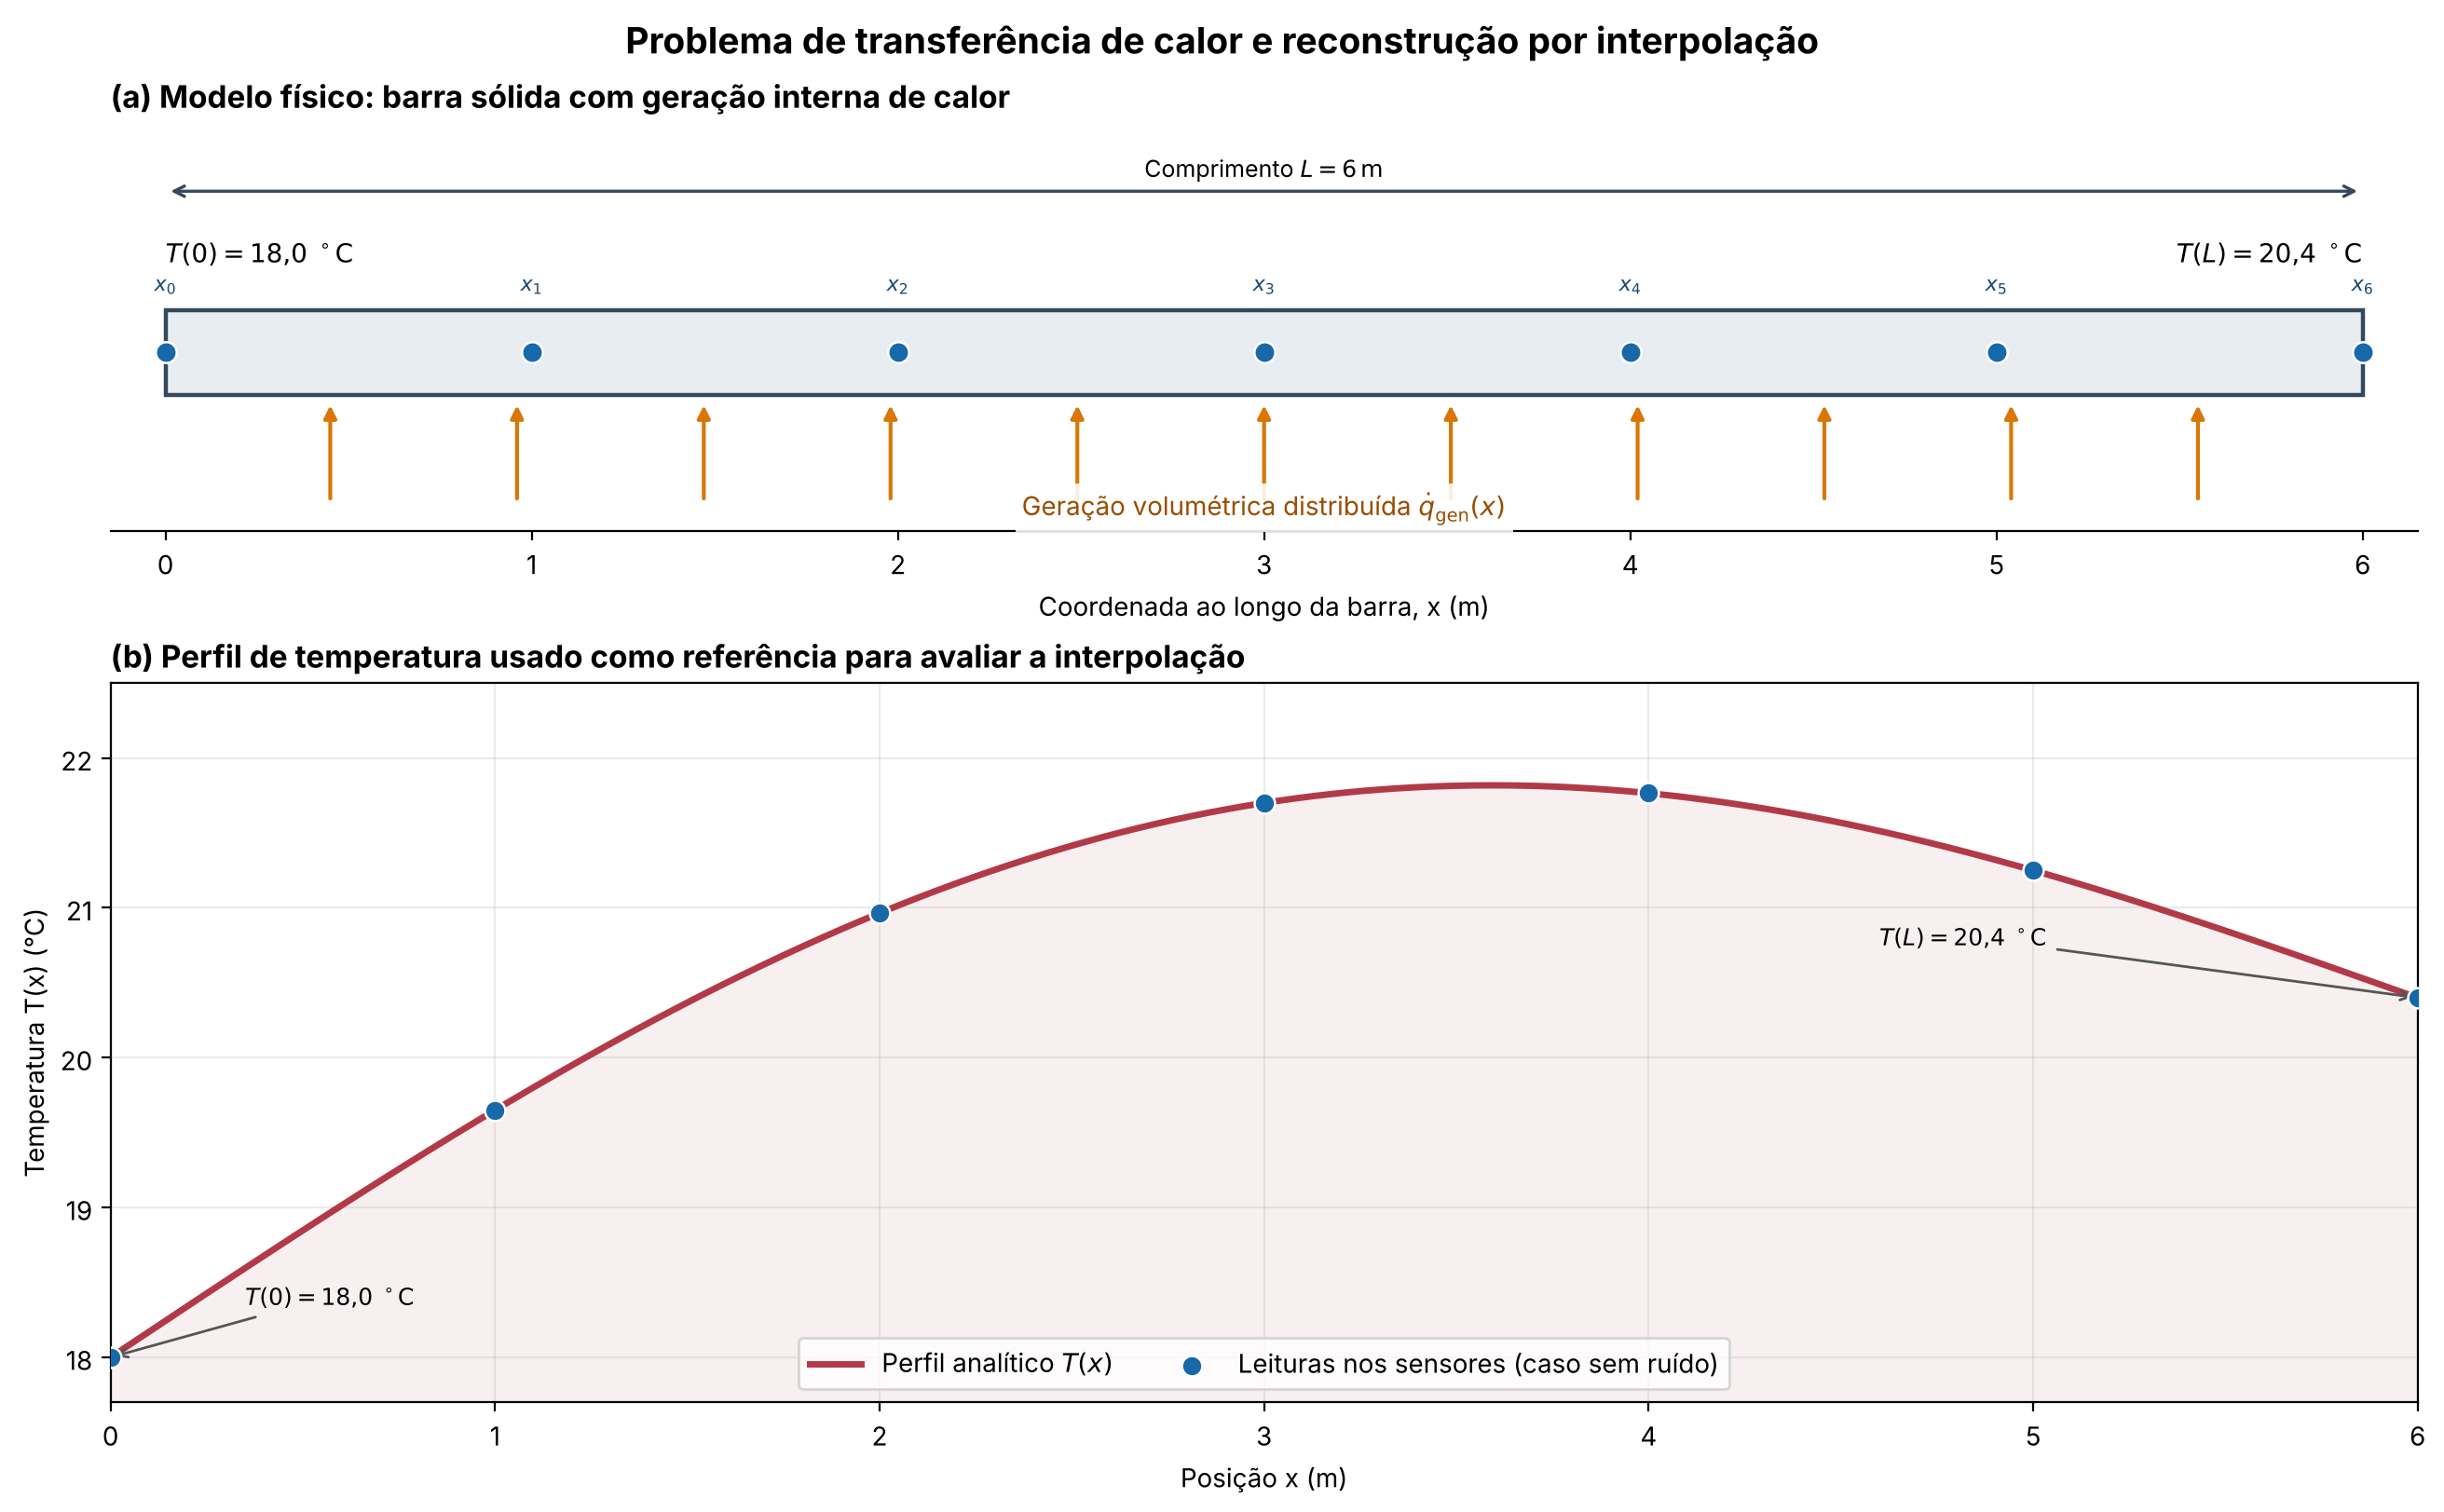

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468e-05,1.918e-05,3.271e-05
1,Spline cúbica natural,5.060e-04,1.841e-04,2.391e-04
2,Spline quadrática,2.393e-02,1.495e-02,1.647e-02
3,Spline linear,8.229e-02,3.651e-02,4.397e-02


Lagrange global          erro máximo NOS nós = 0.0e+00 °C
Spline linear            erro máximo NOS nós = 0.0e+00 °C
Spline quadrática        erro máximo NOS nós = 0.0e+00 °C
Spline cúbica natural    erro máximo NOS nós = 0.0e+00 °C


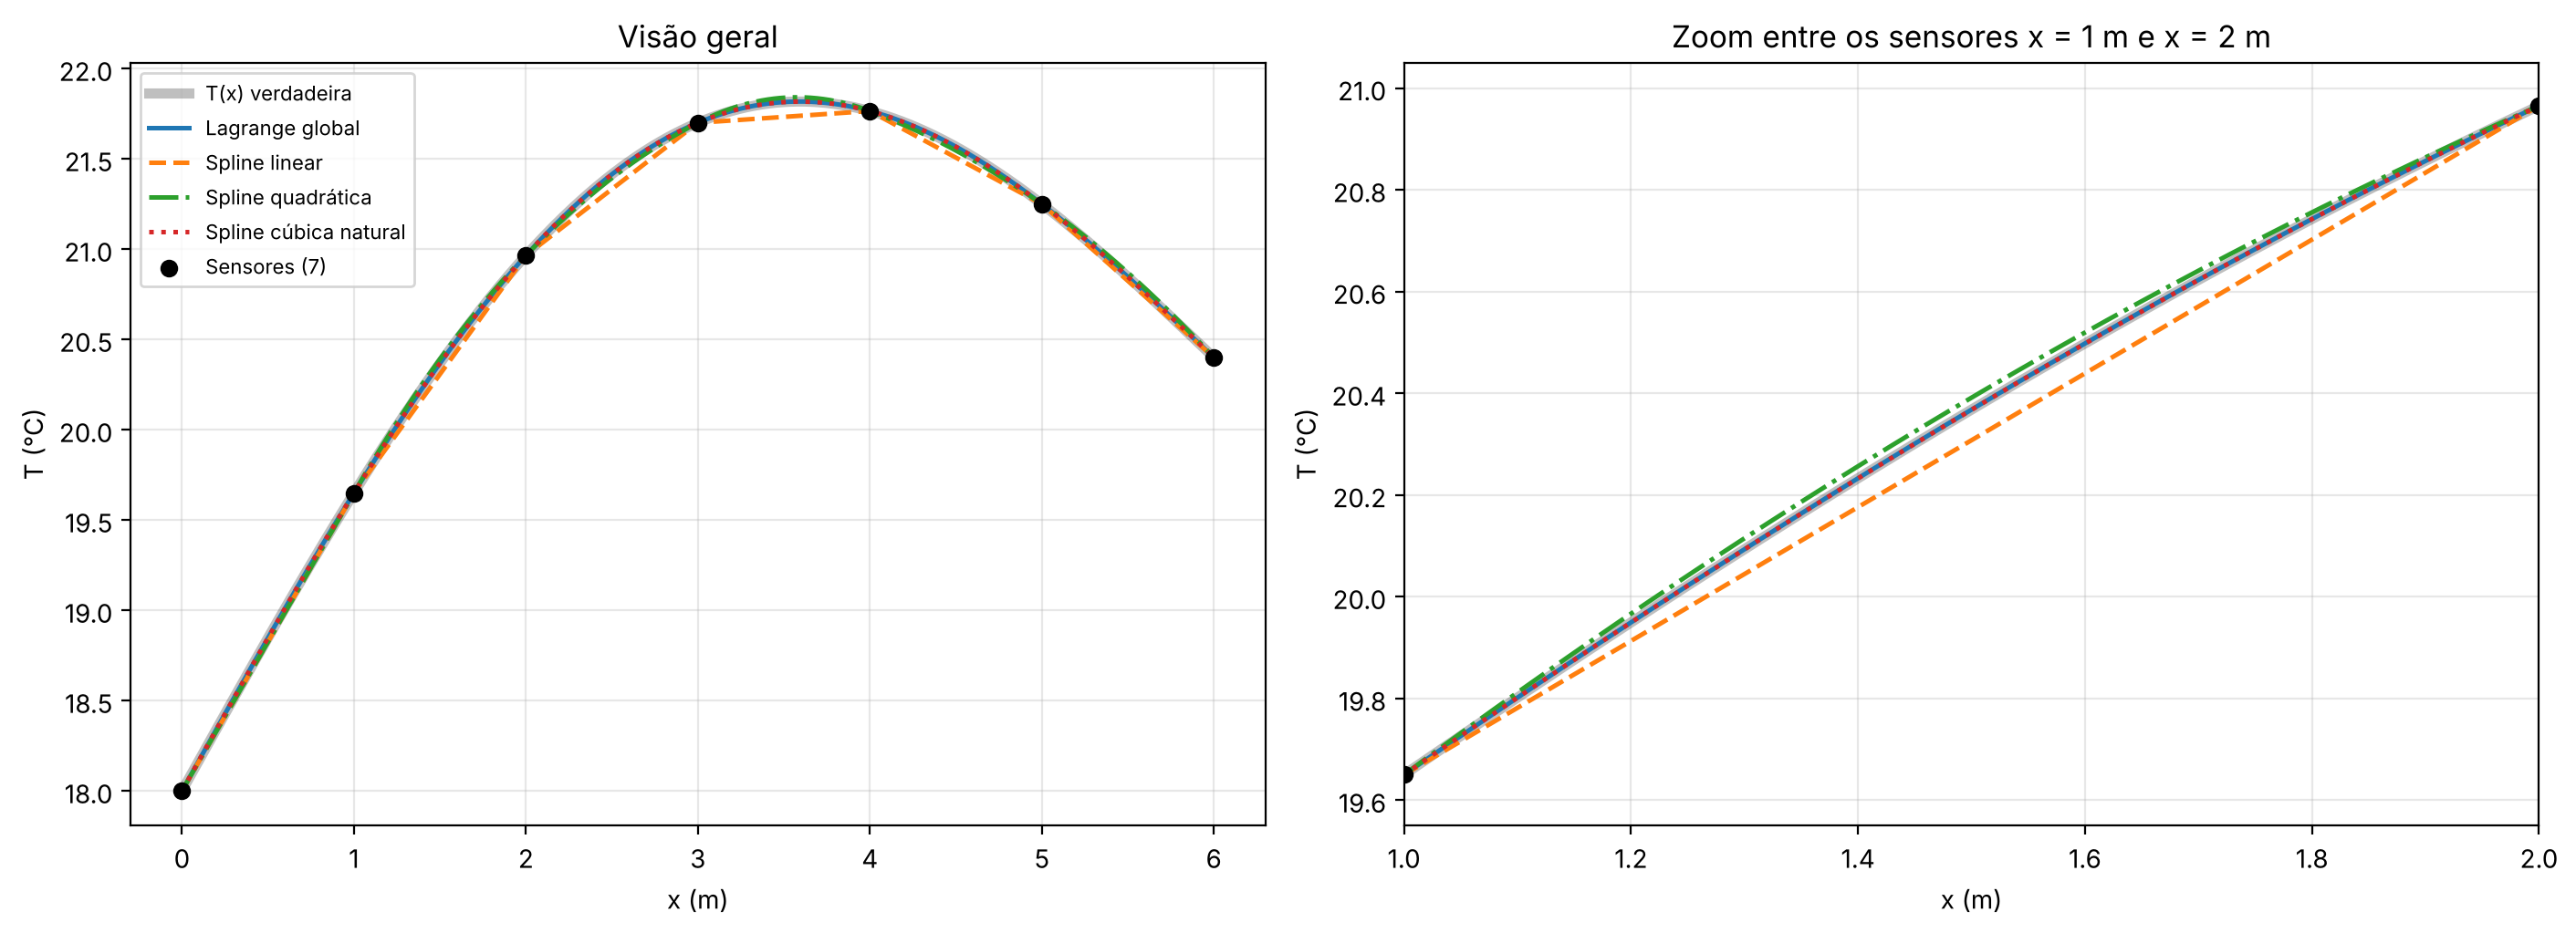

In [4]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Métricas na malha fina (2001 pontos => a maioria está ENTRE os nós)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
with pd.option_context("display.float_format", "{:.3e}".format):
    display(metricas_7)

# Sanidade: nos nós, a interpolação deve reproduzir os dados (erro ~ arredondamento)
for nome, f in metodos_7.items():
    print(f"{nome:24s} erro máximo NOS nós = {np.max(np.abs(f(x_nos_7) - y_nos_7)):.1e} °C")

# Gráfico: temperaturas (visão geral + zoom entre nós)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
estilos = ["-", "--", "-.", ":"]
for ax in (ax1, ax2):
    ax.plot(x_fino, T_fino, color="k", lw=4, alpha=0.25, label="T(x) verdadeira")
    for (nome, f), ls in zip(metodos_7.items(), estilos):
        ax.plot(x_fino, f(x_fino), ls, lw=1.8, label=nome)
    ax.scatter(x_nos_7, y_nos_7, color="k", zorder=5, label="Sensores (7)")
    ax.set_xlabel("x (m)"); ax.set_ylabel("T (°C)"); ax.grid(alpha=0.3)
ax1.set_title("Visão geral"); ax1.legend(fontsize=8)
ax2.set_xlim(1.0, 2.0); ax2.set_ylim(19.55, 21.05)
ax2.set_title("Zoom entre os sensores x = 1 m e x = 2 m")
plt.show()

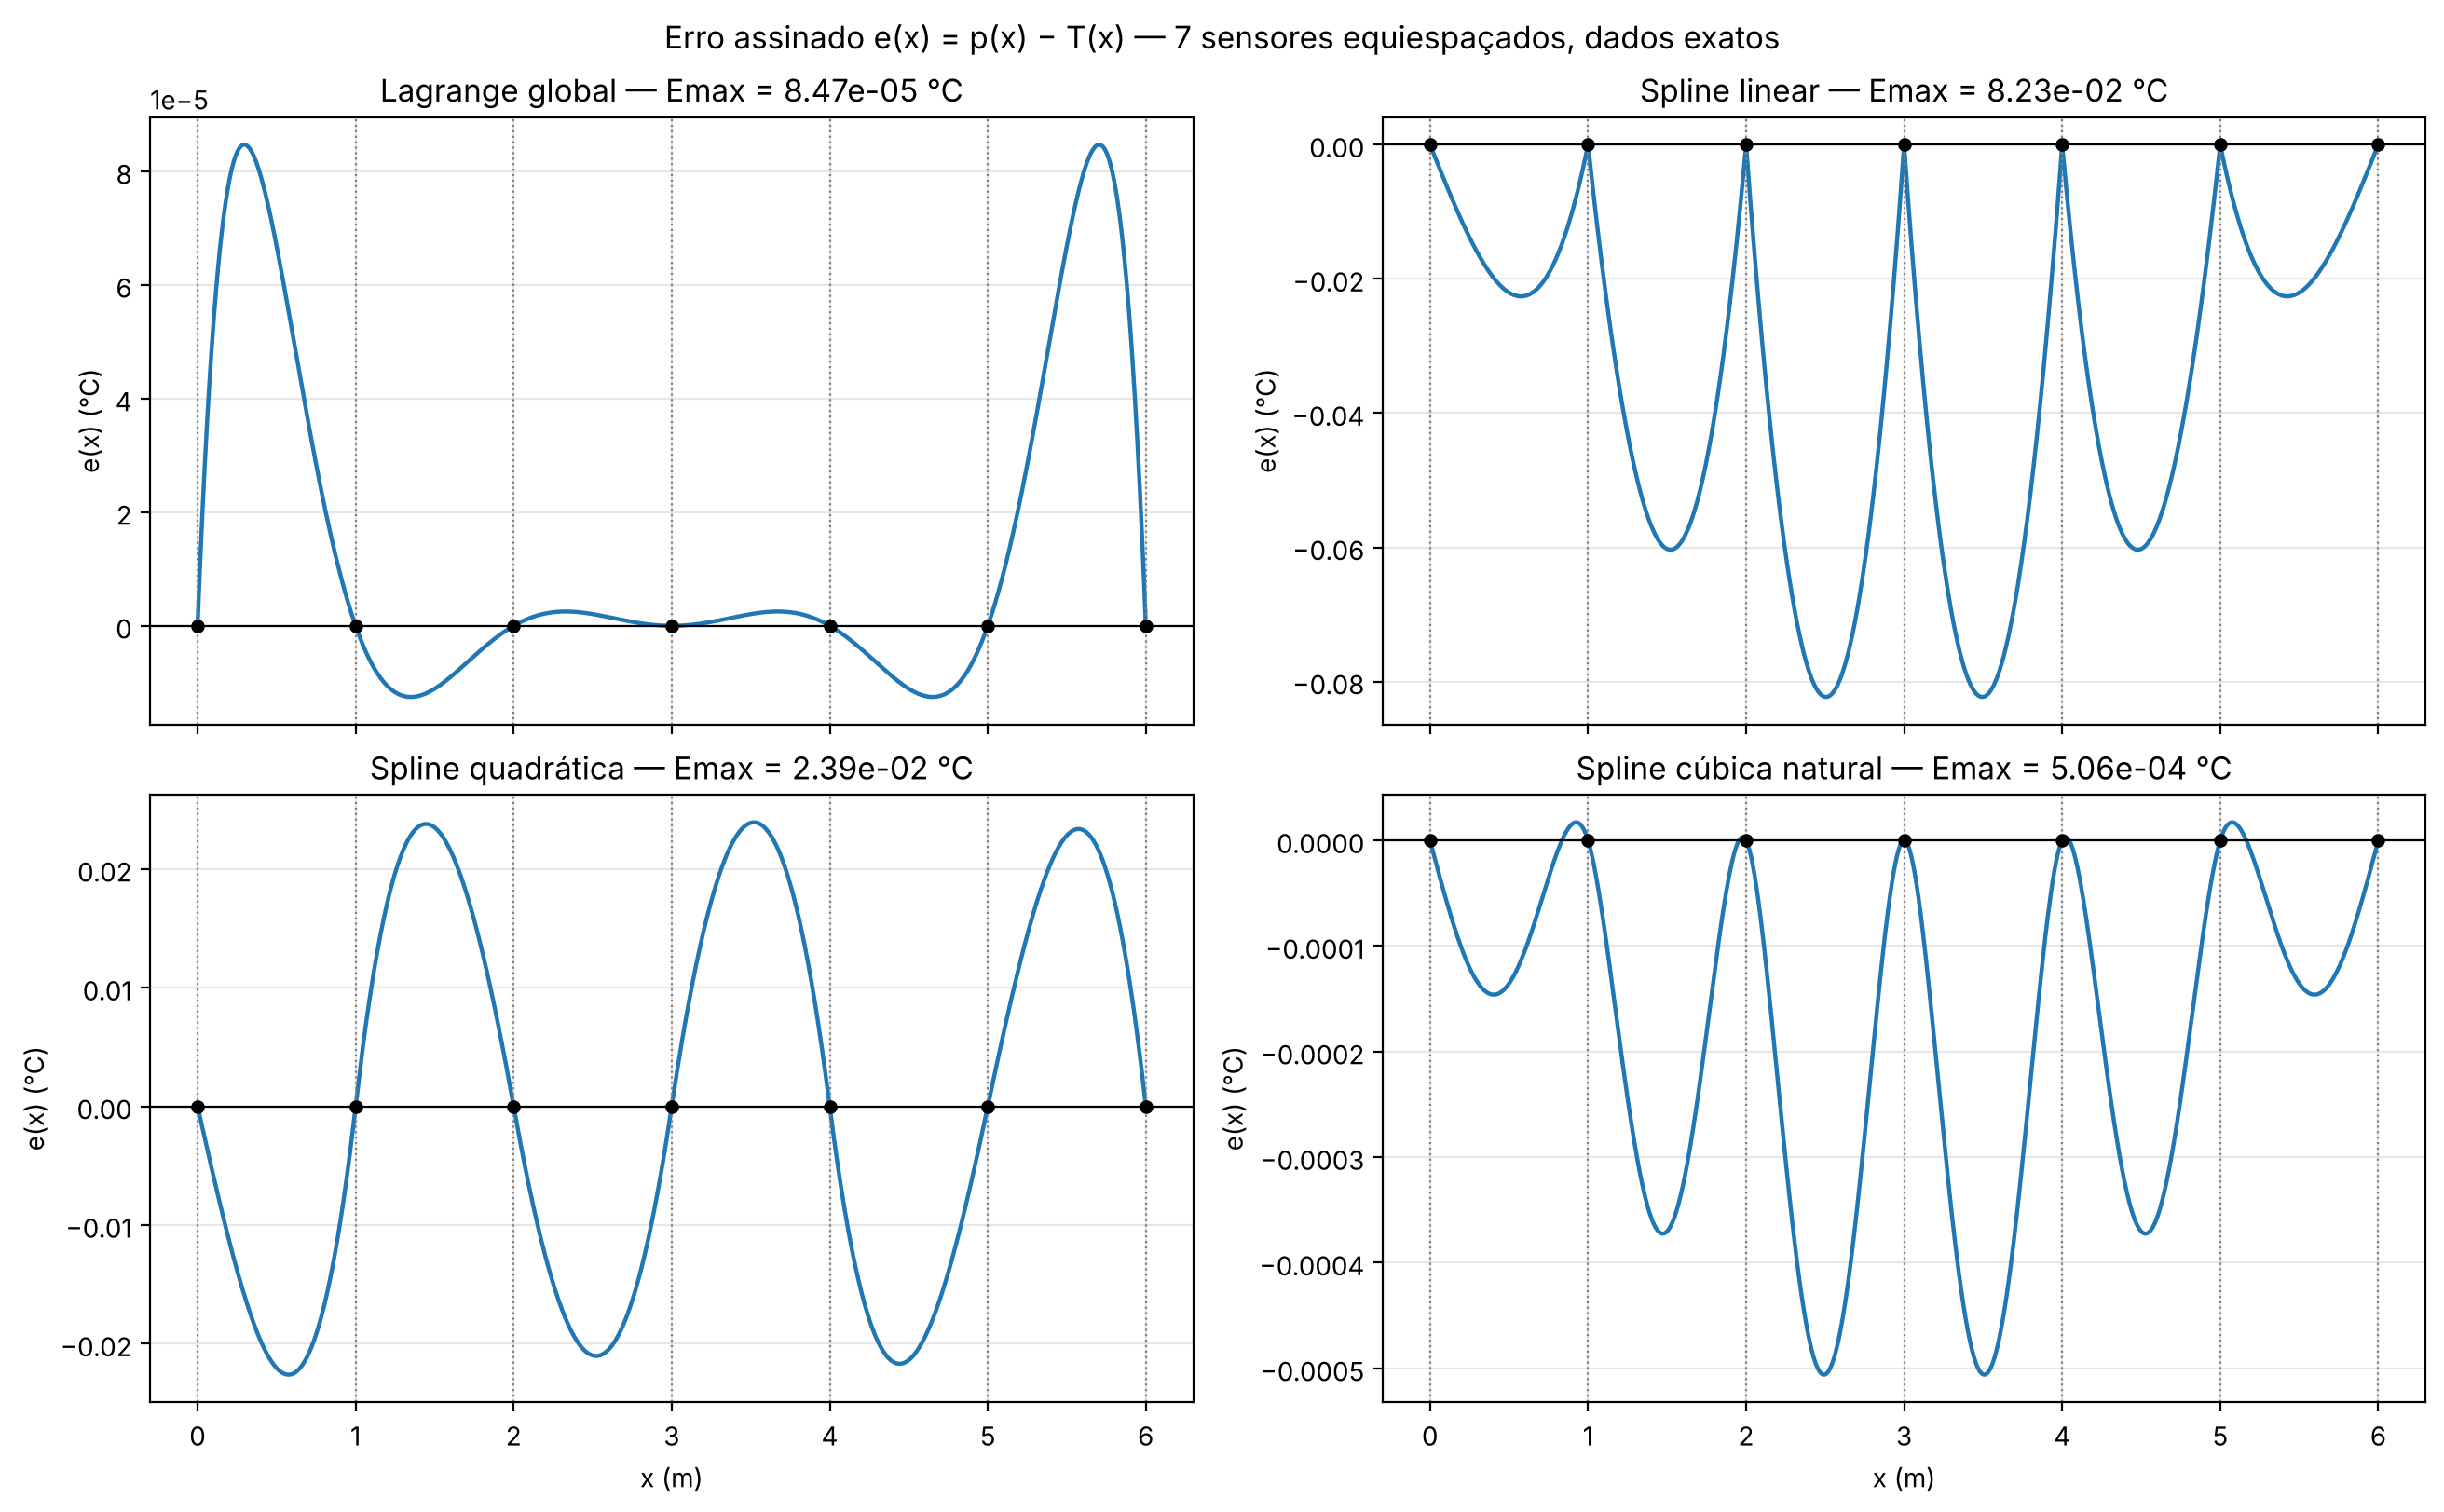

Lagrange global          pior erro em x = 5.71 m  (e = +8.47e-05 °C)
Spline linear            pior erro em x = 2.50 m  (e = -8.23e-02 °C)
Spline quadrática        pior erro em x = 3.52 m  (e = +2.39e-02 °C)
Spline cúbica natural    pior erro em x = 3.51 m  (e = -5.06e-04 °C)


In [5]:
# Erro assinado e(x) = p(x) - T(x), um painel por método (escalas diferentes de propósito)
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharex=True, constrained_layout=True)
for ax, (nome, f) in zip(axs.ravel(), metodos_7.items()):
    erro = f(x_fino) - T_fino
    ax.plot(x_fino, erro, lw=1.6)
    ax.axhline(0, color="k", lw=0.8)
    for xn in x_nos_7:
        ax.axvline(xn, color="gray", ls=":", lw=0.8)
    ax.scatter(x_nos_7, np.zeros_like(x_nos_7), color="k", s=18, zorder=5)
    ax.set_title(f"{nome} — Emax = {np.max(np.abs(erro)):.2e} °C")
    ax.set_ylabel("e(x) (°C)"); ax.grid(alpha=0.3)
for ax in axs[1]:
    ax.set_xlabel("x (m)")
fig.suptitle("Erro assinado e(x) = p(x) − T(x) — 7 sensores equiespaçados, dados exatos")
plt.show()

# Onde (em x) cada método erra mais?
for nome, f in metodos_7.items():
    erro = f(x_fino) - T_fino
    print(f"{nome:24s} pior erro em x = {x_fino[np.argmax(np.abs(erro))]:.2f} m  (e = {erro[np.argmax(np.abs(erro))]:+.2e} °C)")

In [6]:
# Ordem de convergência das splines: dobrar o nº de intervalos (h -> h/2) e ver por quanto o Emax cai.
# Se Emax ~ h^p, então a razão Emax(h)/Emax(h/2) ≈ 2^p  (p observado = log2 da razão).
from math import factorial

linhas = []
for N in (7, 13, 25, 49, 97):                   # 6, 12, 24, 48, 96 intervalos
    xn = np.linspace(x_min, x_max, N); yn = temperatura_real(xn)
    coef = spline_quadratica_coef(xn, yn)
    erros = {"Spline linear":        interp1d(xn, yn)(x_fino) - T_fino,
             "Spline quadrática":    spline_quadratica_avalia(xn, coef, x_fino) - T_fino,
             "Spline cúbica natural": CubicSpline(xn, yn, bc_type="natural")(x_fino) - T_fino}
    linhas.append({"N": N, "h (m)": L/(N-1), **{k: np.max(np.abs(v)) for k, v in erros.items()}})
tab_ordem = pd.DataFrame(linhas)
for nome in ("Spline linear", "Spline quadrática", "Spline cúbica natural"):
    tab_ordem[f"p ({nome})"] = np.log2(tab_ordem[nome].shift(1)/tab_ordem[nome])
with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 250, "display.max_columns", 12):
    display(tab_ordem)

# Teoria x experimento para Lagrange com 7 nós:  |e(x)| ≤ max|T⁽⁷⁾|/7! · max|Π(x − x_i)|
# T⁽⁷⁾(x) = ±2,5·(π/L)^7·cos(πx/L)  (a parte linear some após 2 derivadas)
prod_no = np.max(np.abs(np.prod(x_fino[:, None] - x_nos_7[None, :], axis=1)))
cota = 2.5*(np.pi/L)**7/factorial(7)*prod_no
emax_lag = metricas_7.set_index("Método").loc["Lagrange global", "Erro máximo (°C)"]
print(f"Lagrange (7 nós): cota teórica = {cota:.2e} °C  >=  erro observado = {emax_lag:.2e} °C  (cota/observado = {cota/emax_lag:.1f})")

,N,h (m),Spline linear,Spline quadrática,Spline cúbica natural,p (Spline linear),p (Spline quadrática),p (Spline cúbica natural)
0,7,1,0.0823,0.0239,0.000506,NaN,NaN,NaN
1,13,0.5,0.0212,0.00291,3.08e-05,1.96,3.04,4.04
2,25,0.25,0.00534,0.000361,1.92e-06,1.99,3.01,4.01
3,49,0.125,0.00134,4.5e-05,1.2e-07,2,3,4
4,97,0.0625,0.000334,5.62e-06,7.45e-09,2,3,4


Lagrange (7 nós): cota teórica = 5.13e-04 °C  >=  erro observado = 8.47e-05 °C  (cota/observado = 6.1)


### Análise da Etapa 1 — dados exatos, 7 sensores

**Resultado (malha fina, 2001 pontos):**

| Método | Erro máx. (°C) | RMSE (°C) |
|---|---|---|
| Lagrange global | 8,5·10⁻⁵ | 3,3·10⁻⁵ |
| Spline cúbica natural | 5,1·10⁻⁴ | 2,4·10⁻⁴ |
| Spline quadrática | 2,4·10⁻² | 1,6·10⁻² |
| Spline linear | 8,2·10⁻² | 4,4·10⁻² |

**Leitura dos resultados**

1. **O erro nos nós é zero, mas isso não diz nada sobre a qualidade.** Todo interpolador reproduz os dados; o que importa é o erro *entre* os sensores. Ele é máximo no meio dos intervalos (linear: x = 2,5 m, ponto médio de [2, 3]).
2. **A ordem do método explica o ranking.** A tabela de refinamento mostra p ≈ 2 (linear), p ≈ 3 (quadrática) e p ≈ 4 (cúbica): ao dobrar o número de intervalos, o erro cai ~4×, ~8× e ~16×. Para a linear, o erro é ≈ h²·max|T″|/8 = 1²·0,66/8 ≈ 0,083 °C, exatamente o observado.
3. **Por que o Lagrange global vence com 7 sensores?** O perfil é uma função analítica (senoide + reta). Na fórmula do erro, |e(x)| ≤ max|T⁽⁷⁾|/7! · max|Π(x − xᵢ)|, a sétima derivada é minúscula (cada derivada multiplica por π/L ≈ 0,52 m⁻¹). A cota teórica calculada (5,1·10⁻⁴ °C) é maior que o erro observado (8,5·10⁻⁵ °C), como deve ser, e da mesma ordem de grandeza.
4. **Isso é uma vitória condicionada à suavidade.** Com dados exatos, poucos nós e função suave, o polinômio global é excelente; as Etapas 2 e 3 mostram quando ele deixa de ser.
5. **A spline quadrática deste notebook tem desempenho intermediário:** ordem 3 (não chega à ordem 4 da cúbica) e, com 7 sensores, erro ≈ 47× maior que o da cúbica (2,4·10⁻² vs 5,1·10⁻⁴ °C). Aqui a condição c₀ = 0 é exata (T″(0) = 0), então a diferença vem da ordem do método e não de uma condição de contorno errada.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [7]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

def erro_lagrange(xn, f_ref=temperatura_real, f_ref_fino=T_fino):
    """Lagrange (forma baricêntrica) nos nós xn; retorna (Emax, RMSE) na malha fina."""
    p = BarycentricInterpolator(xn, f_ref(xn))
    e = p(x_fino) - f_ref_fino
    return np.max(np.abs(e)), np.sqrt(np.mean(e**2))

linhas = []
for N in (5, 9, 13, 17):
    emax_eq, rmse_eq = erro_lagrange(np.linspace(x_min, x_max, N))
    emax_ch, rmse_ch = erro_lagrange(nos_chebyshev_lobatto(x_min, x_max, N))
    linhas.append({"N": N,
                   "Emax equi (°C)": emax_eq, "Emax Cheb (°C)": emax_ch, "Emax equi/Cheb": emax_eq/emax_ch,
                   "RMSE equi (°C)": rmse_eq, "RMSE Cheb (°C)": rmse_ch, "RMSE equi/Cheb": rmse_eq/rmse_ch})
tabela_nos = pd.DataFrame(linhas)
with pd.option_context("display.float_format", "{:.3e}".format, "display.width", 200):
    display(tabela_nos)

,N,Emax equi (°C),Emax Cheb (°C),Emax equi/Cheb,RMSE equi (°C),RMSE Cheb (°C),RMSE equi/Cheb
0,5,4.530e-03,2.327e-03,1.947e+00,2.160e-03,1.533e-03,1.409e+00
1,9,1.044e-06,2.168e-07,4.814e+00,3.438e-07,1.202e-07,2.860e+00
2,13,5.909e-11,3.627e-12,1.629e+01,1.546e-11,1.932e-12,8.000e+00
3,17,1.990e-12,1.421e-14,1.400e+02,2.445e-13,3.756e-15,6.510e+01


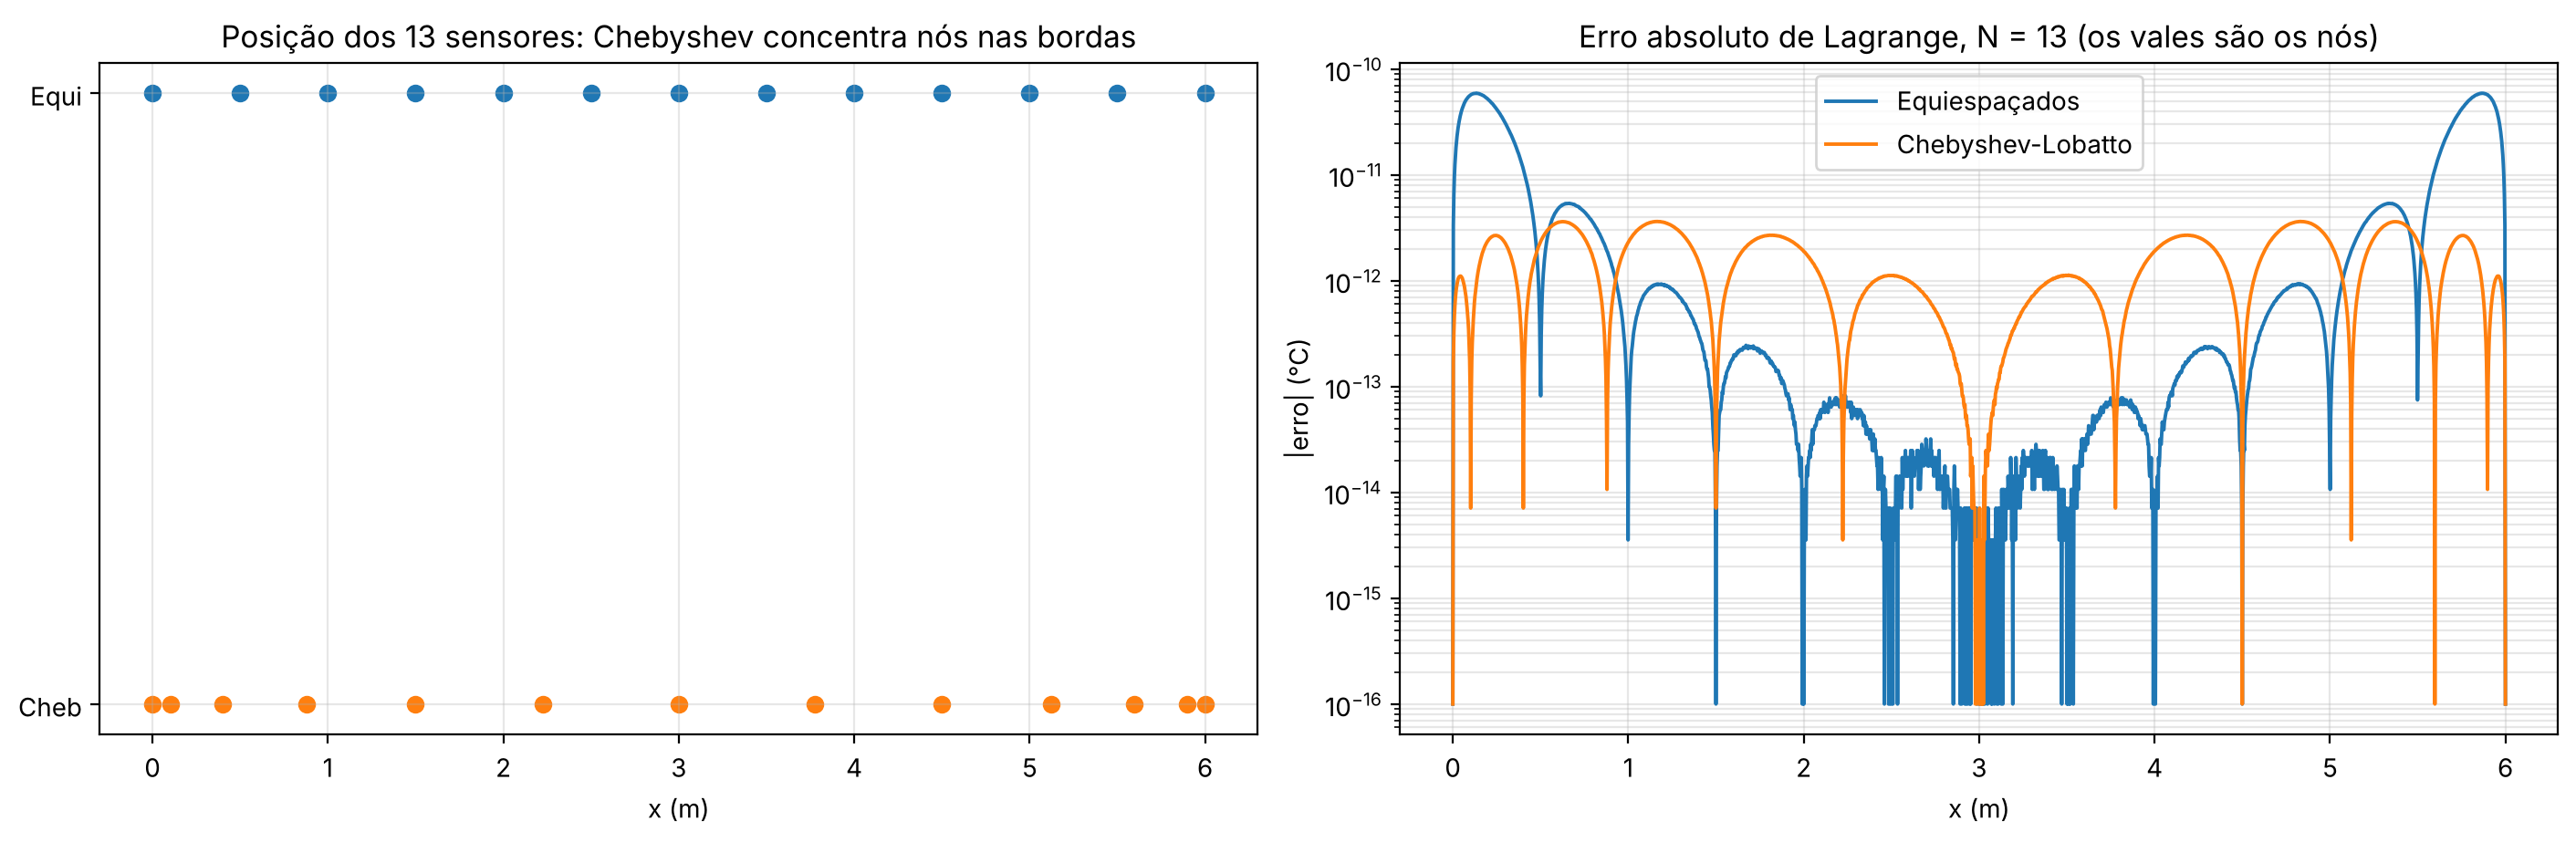

In [8]:
# Visualização: onde ficam os nós e onde está o erro (N = 13)
N = 13
xe, xc = np.linspace(x_min, x_max, N), nos_chebyshev_lobatto(x_min, x_max, N)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
ax1.scatter(xe, np.ones(N), label="Equiespaçados"); ax1.scatter(xc, np.zeros(N), label="Chebyshev-Lobatto")
ax1.set_yticks([0, 1]); ax1.set_yticklabels(["Cheb", "Equi"]); ax1.set_xlabel("x (m)")
ax1.set_title(f"Posição dos {N} sensores: Chebyshev concentra nós nas bordas"); ax1.grid(alpha=0.3)
for xn, rot in ((xe, "Equiespaçados"), (xc, "Chebyshev-Lobatto")):
    e = np.abs(BarycentricInterpolator(xn, temperatura_real(xn))(x_fino) - T_fino)
    ax2.semilogy(x_fino, np.maximum(e, 1e-16), lw=1.4, label=rot)
ax2.set_xlabel("x (m)"); ax2.set_ylabel("|erro| (°C)"); ax2.grid(alpha=0.3, which="both"); ax2.legend()
ax2.set_title(f"Erro absoluto de Lagrange, N = {N} (os vales são os nós)")
plt.show()

,N,Emax equi,Emax Cheb
0,5,4.384e-01,4.600e-01
1,9,1.045e+00,2.047e-01
2,13,3.663e+00,8.440e-02
3,17,1.439e+01,3.671e-02
4,25,2.572e+02,8.166e-03


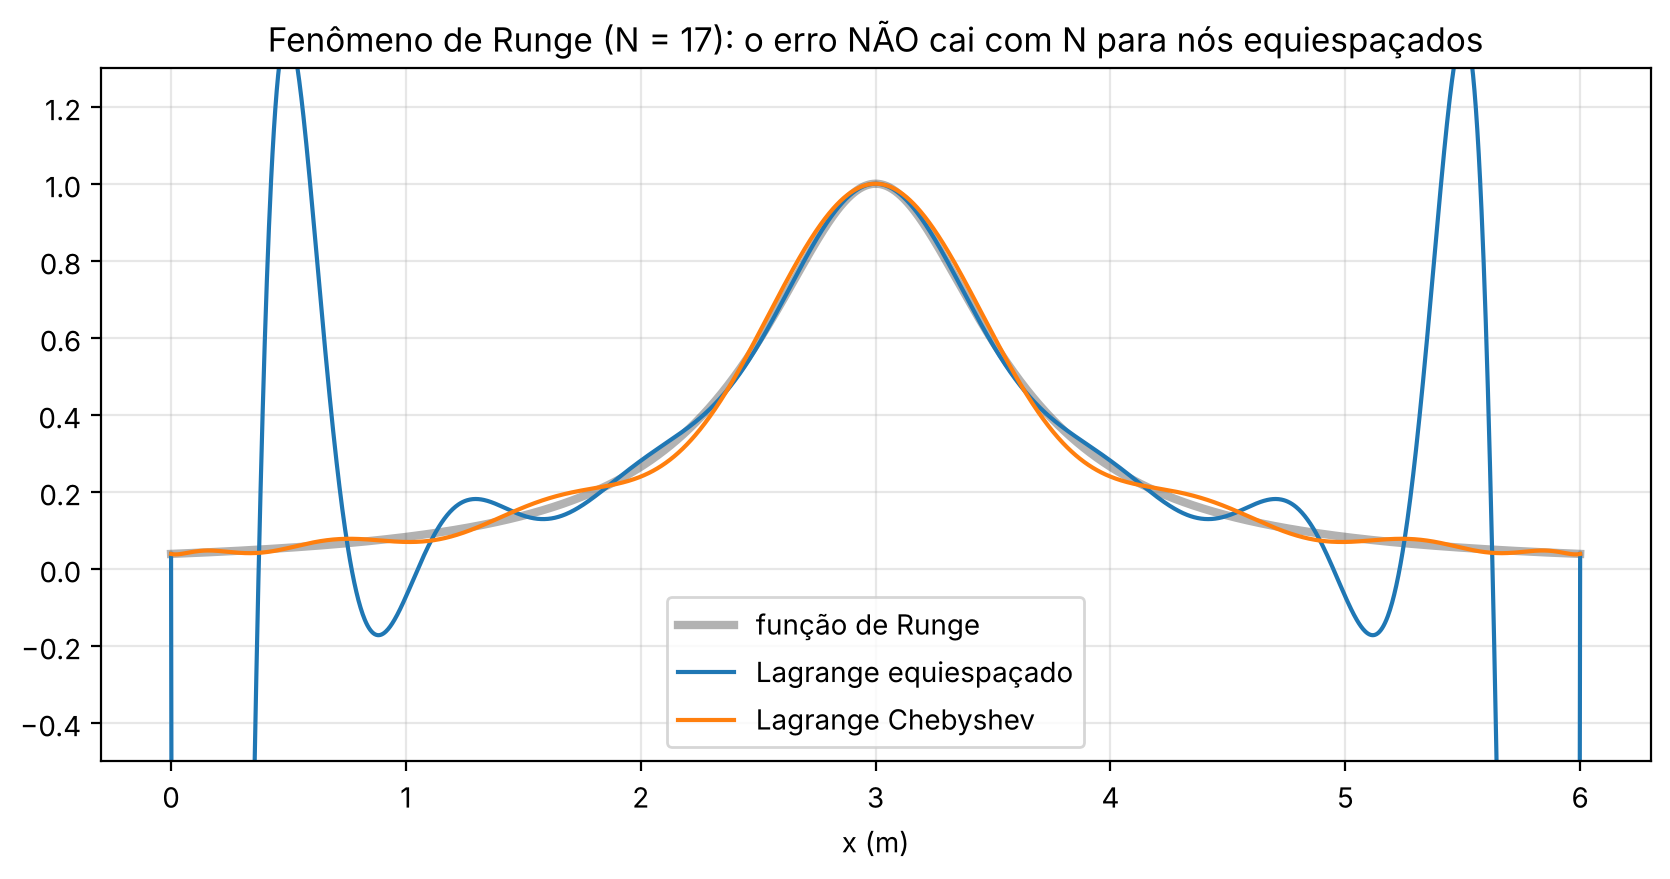

In [9]:
# CONTRAPONTO: o mesmo experimento com uma função NÃO tão suave (Runge) para testar a "Atenção" do enunciado.
def f_runge(x):
    """Função de Runge reescalada: 1/(1+25 s²), s = 2x/L − 1 ∈ [−1, 1]. Tem polos complexos em s = ±i/5."""
    s = 2*np.asarray(x, float)/L - 1
    return 1/(1 + 25*s**2)

f_runge_fino = f_runge(x_fino)
linhas = []
for N in (5, 9, 13, 17, 25):
    emax_eq, _ = erro_lagrange(np.linspace(x_min, x_max, N), f_runge, f_runge_fino)
    emax_ch, _ = erro_lagrange(nos_chebyshev_lobatto(x_min, x_max, N), f_runge, f_runge_fino)
    linhas.append({"N": N, "Emax equi": emax_eq, "Emax Cheb": emax_ch})
with pd.option_context("display.float_format", "{:.3e}".format):
    display(pd.DataFrame(linhas))

N = 17
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x_fino, f_runge_fino, "k", lw=3, alpha=0.3, label="função de Runge")
for xn, rot in ((np.linspace(x_min, x_max, N), "Lagrange equiespaçado"),
                (nos_chebyshev_lobatto(x_min, x_max, N), "Lagrange Chebyshev")):
    ax.plot(x_fino, BarycentricInterpolator(xn, f_runge(xn))(x_fino), label=rot)
ax.set_ylim(-0.5, 1.3); ax.set_title(f"Fenômeno de Runge (N = {N}): o erro NÃO cai com N para nós equiespaçados")
ax.set_xlabel("x (m)"); ax.grid(alpha=0.3); ax.legend(); plt.show()

### Análise da Etapa 2 — número e posição dos sensores (Lagrange)

**O que a tabela mostra.** Os nós de Chebyshev-Lobatto reduzem o erro máximo por fatores de ≈ 1,9× (N = 5), 4,8× (N = 9), 16× (N = 13) e 140× (N = 17), e o RMSE por ≈ 1,4×, 2,9×, 8× e 65×. **O ganho cresce com N.**

**Por que isso acontece.** O erro de interpolação é proporcional ao polinômio nodal Π(x − xᵢ). Nós equiespaçados tornam esse produto grande perto das extremidades (o gráfico da direita mostra o erro de nós equiespaçados concentrado nas pontas), enquanto os nós de Chebyshev equalizam o produto ao longo do intervalo e minimizam seu máximo.

**Cuidado com a interpretação (a "Atenção" do enunciado).**

- Neste perfil, **ambos convergem**: já com N = 9 os erros são ~10⁻⁶ °C, muito abaixo da precisão de qualquer sensor. Com N = 17 ambos já estão no respectivo piso de arredondamento (≈ 10⁻¹² °C para equiespaçado e ≈ 10⁻¹⁴ °C para Chebyshev). Então a vantagem de Chebyshev é real, mas **pouco relevante na prática para este perfil**.
- O fenômeno de Runge **não aparece** aqui porque T(x) é uma função inteira (senoide + reta, sem singularidades no plano complexo). Para provar que isso é uma propriedade *do perfil* e não do método, a célula de contraponto repete o experimento com a função de Runge (polos em s = ±i/5): com nós equiespaçados o erro **cresce** de 0,44 (N = 5) para ≈ 257 (N = 25), enquanto com Chebyshev **cai** de 0,46 para ≈ 8·10⁻³.
- Com N = 5 a vantagem de Chebyshev nem existe para a função de Runge (0,46 vs 0,44): a teoria é assintótica.

**Conclusão prática.** Se for possível escolher onde instalar os sensores, concentrar sensores nas bordas (Chebyshev) é uma escolha segura. Se a posição for imposta (nós equiespaçados), o polinômio global só é confiável para N moderado e perfil suave, o que a Etapa 3 quantifica.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

In [10]:
import time

def lebesgue_const(xn, x_aval):
    """Constante de Lebesgue Λ = max_x Σ_j |l_j(x)|: fator máximo de amplificação de erros nos DADOS.
    Usa a forma baricêntrica: Σ|w_j/(x−x_j)| / |Σ w_j/(x−x_j)|."""
    w = np.array([1.0/np.prod(xn[j] - np.delete(xn, j)) for j in range(len(xn))])
    xa = x_aval[~np.isin(x_aval, xn)]               # evita divisão por zero exatamente nos nós
    t = w[None, :]/(xa[:, None] - xn[None, :])
    return np.max(np.sum(np.abs(t), axis=1)/np.abs(np.sum(t, axis=1)))

def tempo_mediano(fn, rep=21):
    """Mediana de `rep` execuções (robusta a picos do sistema); retorna segundos."""
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

esquemas = {   # nome -> (função que gera os nós, função que constrói o interpolador)
    "Lagrange equiespaçado": (lambda N: np.linspace(x_min, x_max, N),               lambda x, y: BarycentricInterpolator(x, y)),
    "Lagrange Chebyshev":    (lambda N: nos_chebyshev_lobatto(x_min, x_max, N),     lambda x, y: BarycentricInterpolator(x, y)),
    "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N),               lambda x, y: CubicSpline(x, y, bc_type="natural")),
}

dados = []
for N in range(4, 41):
    for nome, (gera_nos, constroi) in esquemas.items():
        xn = gera_nos(N); yn = temperatura_real(xn)
        f = constroi(xn, yn)
        e = f(x_fino) - T_fino
        dados.append({"Método": nome, "N": N,
                      "Emax (°C)": np.max(np.abs(e)), "RMSE (°C)": np.sqrt(np.mean(e**2)),
                      "t_construção (s)": tempo_mediano(lambda: constroi(xn, yn)),
                      "t_avaliação (s)": tempo_mediano(lambda: f(x_fino)),
                      "Lebesgue": lebesgue_const(xn, x_fino) if "Lagrange" in nome else np.nan})
df3 = pd.DataFrame(dados)

# Tabela resumida (alguns N)
resumo = df3[df3.N.isin([4, 5, 6, 7, 9, 13, 17, 25, 33, 40])].pivot(index="N", columns="Método", values=["Emax (°C)", "RMSE (°C)"])
with pd.option_context("display.float_format", "{:.2e}".format, "display.width", 220):
    display(resumo)

def faixas_vencedor(df, col):
    """Compacta 'quem tem o menor erro para cada N' em faixas contíguas de N."""
    venc = df.pivot(index="N", columns="Método", values=col).idxmin(axis=1)
    faixas, ini, atual, ant = [], venc.index[0], venc.iloc[0], venc.index[0]
    for N, v in venc.items():
        if v != atual:
            faixas.append((ini, ant, atual)); ini, atual = N, v
        ant = N
    faixas.append((ini, ant, atual))
    return faixas

for col in ("Emax (°C)", "RMSE (°C)"):
    print(f"\nMenor {col} por faixa de N:")
    for a, b, nome in faixas_vencedor(df3, col):
        print(f"  N = {a:2d}..{b:2d} -> {nome}")

# Quando a spline cúbica supera o Lagrange equiespaçado? (RMSE)
piv = df3.pivot(index="N", columns="Método", values="RMSE (°C)")
ganha_spline = piv.index[piv["Spline cúbica natural"] < piv["Lagrange equiespaçado"]]
print("\nN em que a spline cúbica natural supera o Lagrange equiespaçado (RMSE):", list(ganha_spline))
melhor_lag_eq = df3[df3["Método"] == "Lagrange equiespaçado"].loc[lambda d: d["RMSE (°C)"].idxmin()]
print(f"Melhor RMSE do Lagrange equiespaçado: {melhor_lag_eq['RMSE (°C)']:.2e} °C em N = {int(melhor_lag_eq['N'])}")

# Ordem de convergência empírica
sp = df3[(df3["Método"] == "Spline cúbica natural") & (df3.N >= 15)]
ordem = np.polyfit(np.log(L/(sp.N - 1)), np.log(sp["Emax (°C)"]), 1)[0]
ch = df3[(df3["Método"] == "Lagrange Chebyshev") & (df3.N <= 14)]
fator = 10**(-np.polyfit(ch.N, np.log10(ch["Emax (°C)"]), 1)[0])
print(f"\nSpline cúbica: Emax ~ h^{ordem:.2f} (ordem algébrica ≈ 4)")
print(f"Lagrange Chebyshev (N ≤ 14): o erro cai por um fator ≈ {fator:.1f} a cada nó adicionado (convergência geométrica)")

Emax (°C)                                                      RMSE (°C)                                            
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural
N                                                                                                                                   
4                1.43e-01              1.09e-01              1.02e-02           8.09e-02              6.83e-02              4.79e-03
5                2.33e-03              4.53e-03              2.67e-03           1.53e-03              2.16e-03              1.33e-03
6                3.02e-03              3.28e-03              1.12e-03           1.73e-03              1.51e-03              5.13e-04
7                3.35e-05              8.47e-05              5.06e-04           1.73e-05              3.27e-05              2.39e-04
9                2.17e-07              1.04e-06              1.58e-04           1.20e-07              3.44e-07              7.31e-05
13               3.63e-12              5.90e-11              3.08e-05           1.93e-12              1.55e-11              1.41e-05
17               1.07e-14              1.99e-12              9.72e-06           3.90e-15              2.45e-13              4.41e-06
25               1.42e-14              2.71e-10              1.92e-06           4.02e-15              2.55e-11              8.66e-07
33               1.42e-14              9.33e-08              6.05e-07           4.11e-15              5.66e-09              2.73e-07
40               1.78e-14              1.14e-05              2.75e-07           4.20e-15              5.91e-07              1.24e-07


Menor Emax (°C) por faixa de N:
  N =  4.. 4 -> Spline cúbica natural
  N =  5.. 5 -> Lagrange Chebyshev
  N =  6.. 6 -> Spline cúbica natural
  N =  7..40 -> Lagrange Chebyshev

Menor RMSE (°C) por faixa de N:
  N =  4.. 6 -> Spline cúbica natural
  N =  7..40 -> Lagrange Chebyshev

N em que a spline cúbica natural supera o Lagrange equiespaçado (RMSE): [4, 5, 6, 39, 40]
Melhor RMSE do Lagrange equiespaçado: 1.21e-13 °C em N = 15

Spline cúbica: Emax ~ h^4.01 (ordem algébrica ≈ 4)
Lagrange Chebyshev (N ≤ 14): o erro cai por um fator ≈ 12.0 a cada nó adicionado (convergência geométrica)


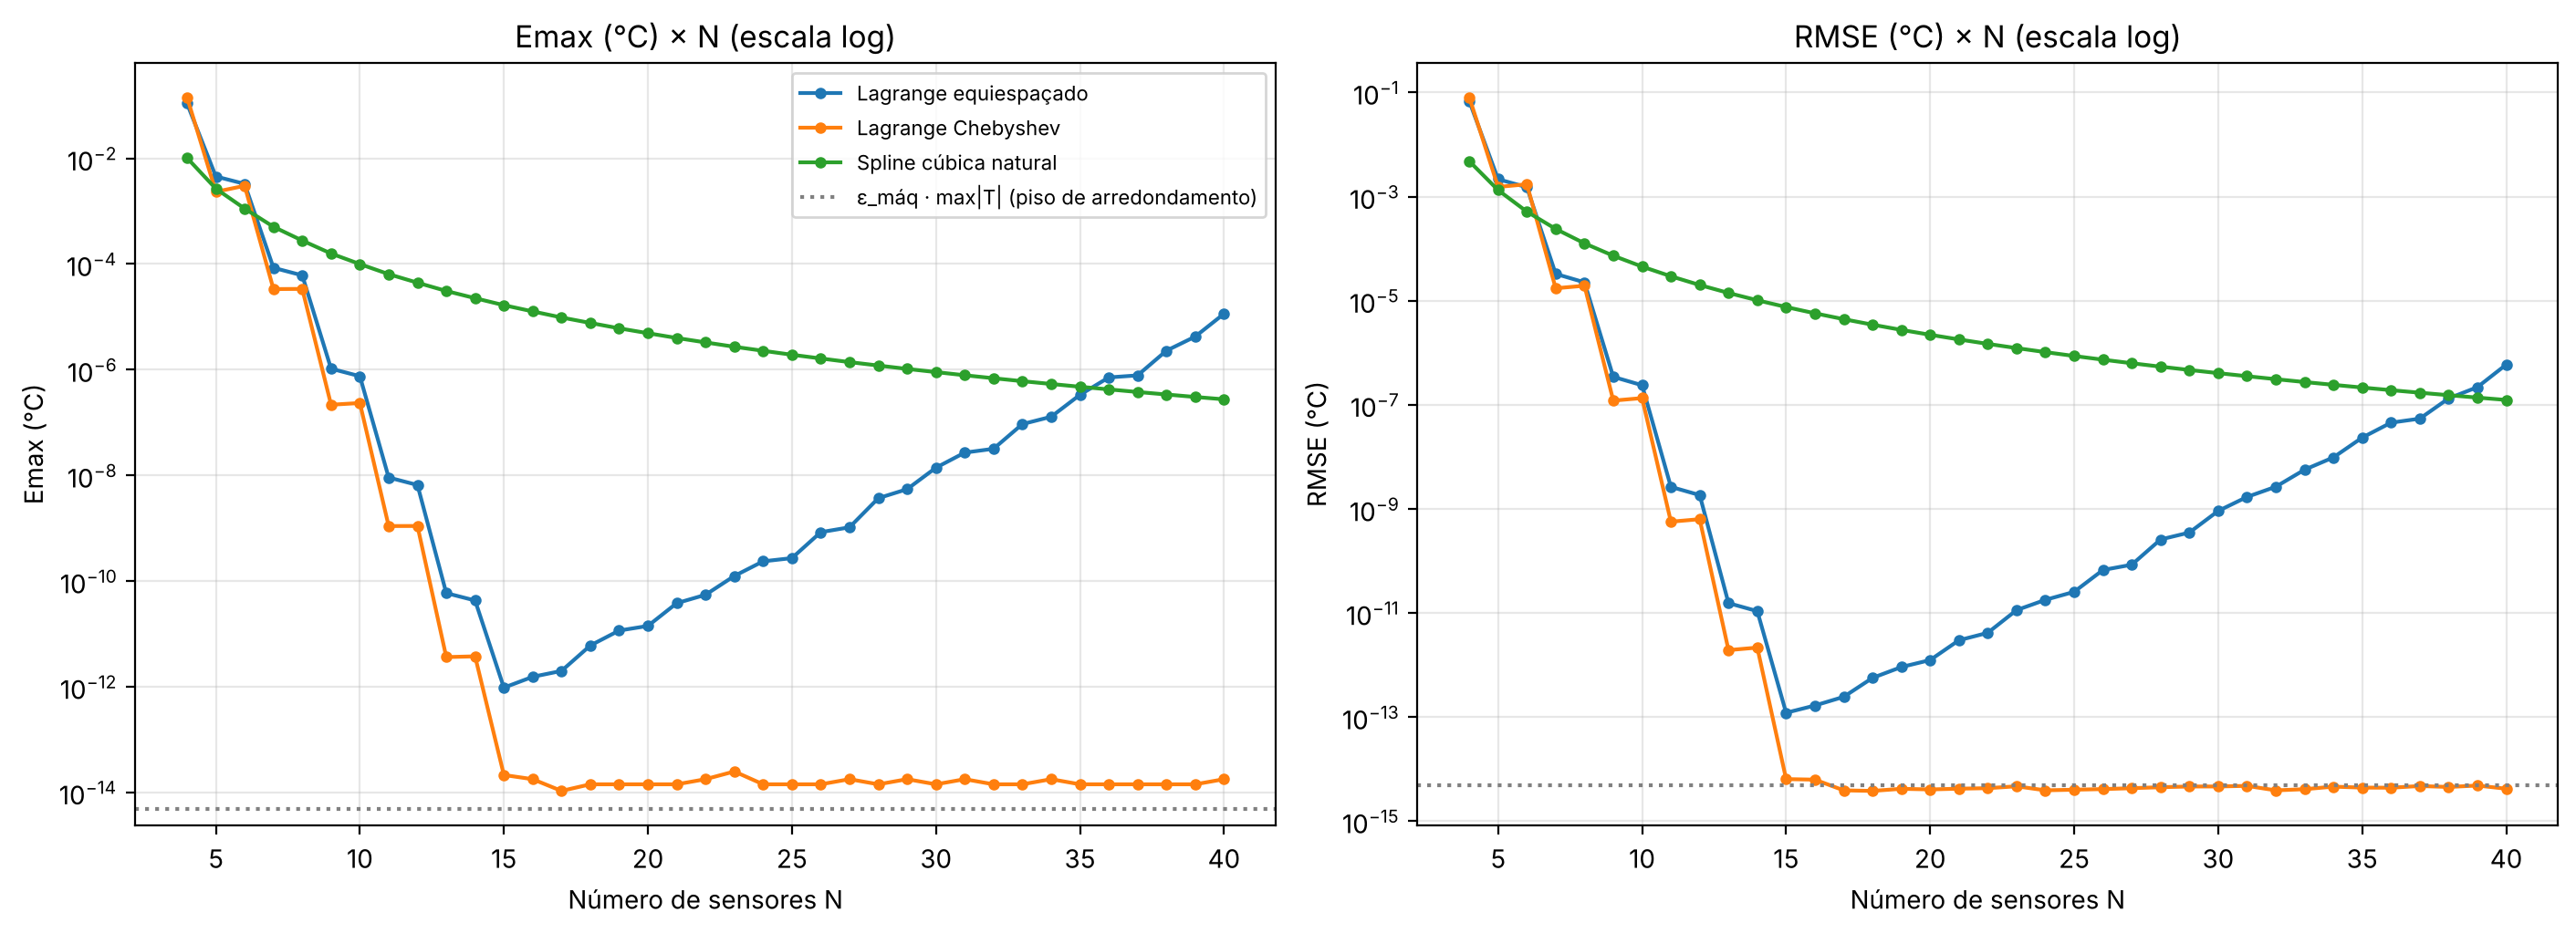

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
eps_ref = np.finfo(float).eps*np.max(np.abs(T_fino))
for ax, col in zip(axs, ("Emax (°C)", "RMSE (°C)")):
    for nome in esquemas:
        d = df3[df3["Método"] == nome]
        ax.semilogy(d.N, d[col], marker="o", ms=3.5, lw=1.5, label=nome)
    ax.axhline(eps_ref, color="gray", ls=":", label="ε_máq · max|T| (piso de arredondamento)")
    ax.set_xlabel("Número de sensores N"); ax.set_ylabel(col); ax.grid(alpha=0.3, which="both")
    ax.set_title(f"{col} × N (escala log)")
axs[0].legend(fontsize=8)
plt.show()

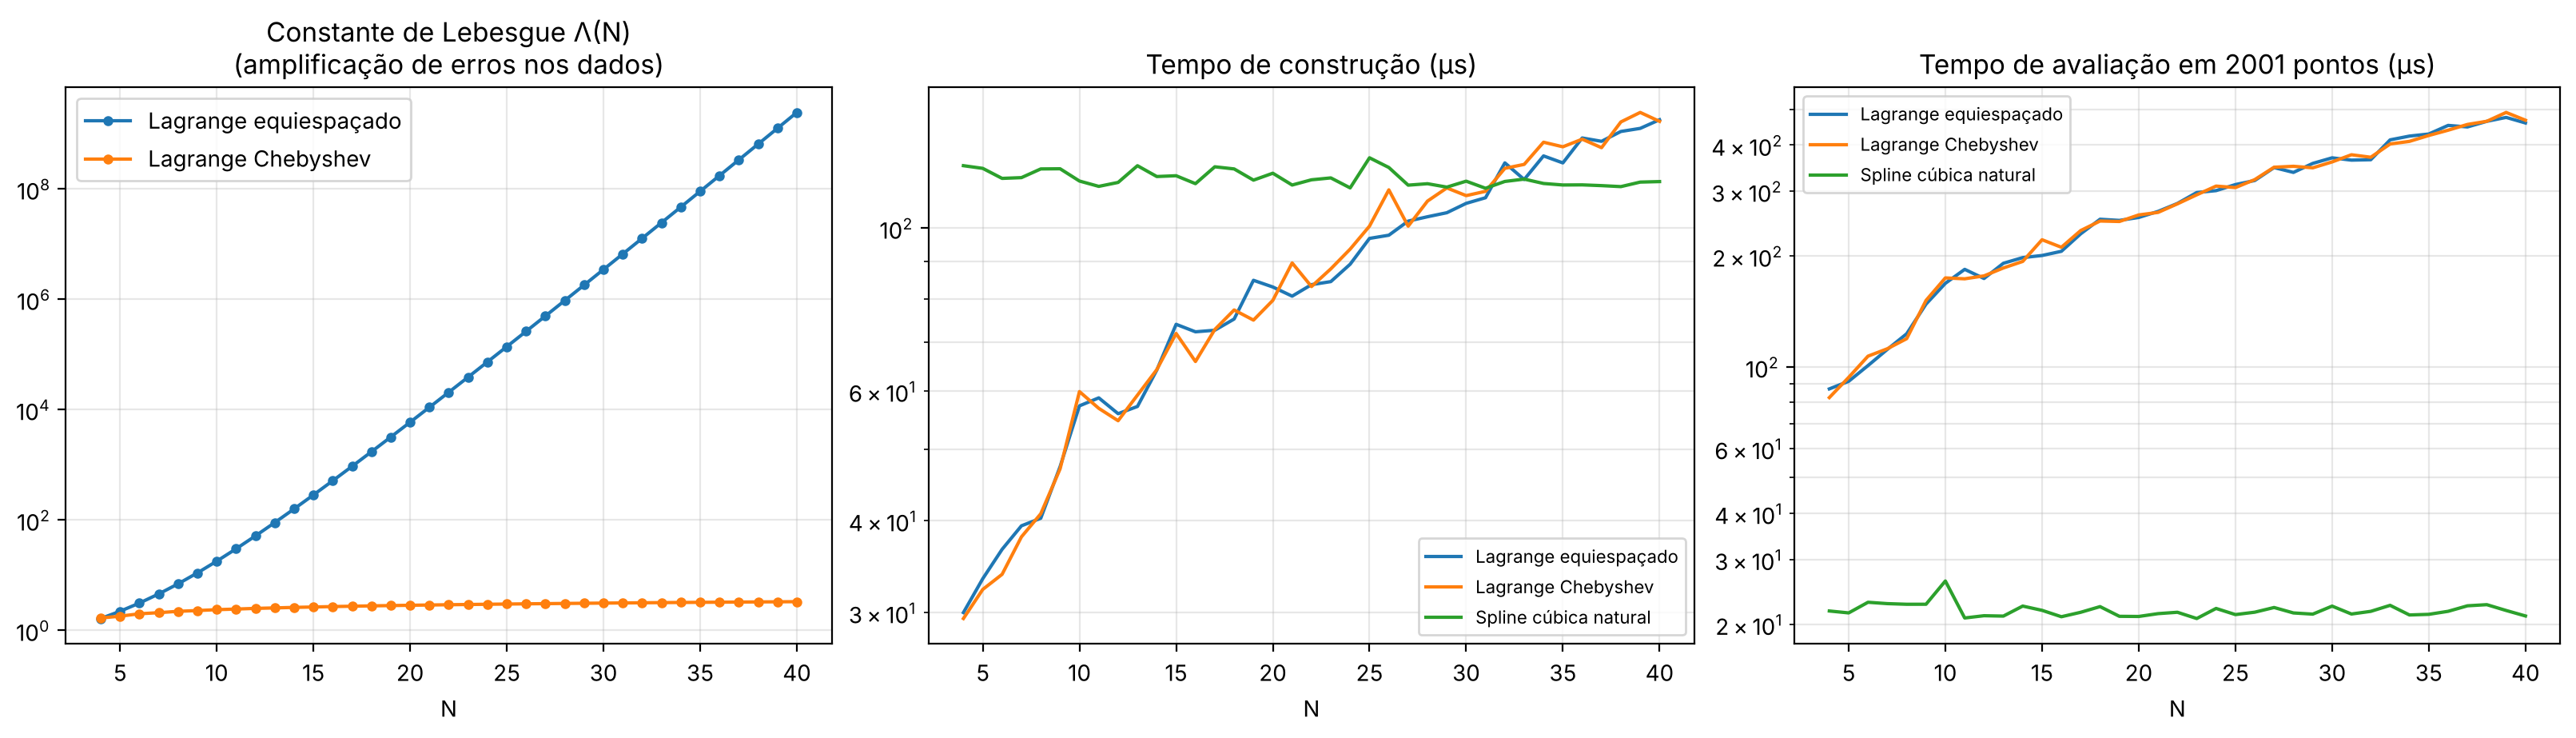

,N,Lagrange: construção (ms),Lagrange: avaliação (ms),Spline: construção (ms),Spline: avaliação (ms)
0,50,0.197,0.646,0.134,0.022
1,100,0.338,1.229,0.152,0.027
2,200,0.733,2.398,0.137,0.024
3,400,1.628,5.128,0.158,0.025
4,800,4.112,9.551,0.173,0.028


,Λ equi,ε·Λ·max|T| equi (°C),Emax equi observado (°C),Λ Cheb,ε·Λ·max|T| Cheb (°C),Emax Cheb observado (°C)
N,,,,,,
9,1.09e+01,5.30e-14,1.04e-06,2.27e+00,1.10e-14,2.17e-07
17,9.34e+02,4.53e-12,1.99e-12,2.72e+00,1.32e-14,1.07e-14
25,1.38e+05,6.68e-10,2.71e-10,2.98e+00,1.45e-14,1.42e-14
33,2.43e+07,1.18e-07,9.33e-08,3.17e+00,1.53e-14,1.42e-14
40,2.42e+09,1.17e-05,1.14e-05,3.29e+00,1.60e-14,1.78e-14


In [12]:
# Custo e estabilidade: constante de Lebesgue e tempos
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for nome in ("Lagrange equiespaçado", "Lagrange Chebyshev"):
    d = df3[df3["Método"] == nome]
    axs[0].semilogy(d.N, d["Lebesgue"], marker="o", ms=3.5, label=nome)
axs[0].set_title("Constante de Lebesgue Λ(N)\n(amplificação de erros nos dados)")
axs[0].set_xlabel("N"); axs[0].grid(alpha=0.3, which="both"); axs[0].legend()
for nome in esquemas:
    d = df3[df3["Método"] == nome]
    axs[1].semilogy(d.N, d["t_construção (s)"]*1e6, label=nome)
    axs[2].semilogy(d.N, d["t_avaliação (s)"]*1e6, label=nome)
axs[1].set_title("Tempo de construção (µs)"); axs[2].set_title(f"Tempo de avaliação em {len(x_fino)} pontos (µs)")
for ax in axs[1:]:
    ax.set_xlabel("N"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.show()

# Escalonamento assintótico (N grande; nós de Chebyshev para Lagrange, para não depender de instabilidade)
linhas = []
for N in (50, 100, 200, 400, 800):
    xc = nos_chebyshev_lobatto(x_min, x_max, N); yc = temperatura_real(xc)
    xe = np.linspace(x_min, x_max, N);           ye = temperatura_real(xe)
    fl, fs = BarycentricInterpolator(xc, yc), CubicSpline(xe, ye, bc_type="natural")
    linhas.append({"N": N,
                   "Lagrange: construção (ms)": 1e3*tempo_mediano(lambda: BarycentricInterpolator(xc, yc), 7),
                   "Lagrange: avaliação (ms)":  1e3*tempo_mediano(lambda: fl(x_fino), 7),
                   "Spline: construção (ms)":   1e3*tempo_mediano(lambda: CubicSpline(xe, ye, bc_type="natural"), 7),
                   "Spline: avaliação (ms)":    1e3*tempo_mediano(lambda: fs(x_fino), 7)})
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 220):
    display(pd.DataFrame(linhas))

# A instabilidade do Lagrange equiespaçado é previsível: piso de arredondamento ≈ ε_máq · Λ · max|T|
eps = np.finfo(float).eps; Tmax = np.max(np.abs(T_fino)); Ns_t = [9, 17, 25, 33, 40]
te = df3[df3["Método"] == "Lagrange equiespaçado"].set_index("N").loc[Ns_t]
tc = df3[df3["Método"] == "Lagrange Chebyshev"].set_index("N").loc[Ns_t]
tab_leb = pd.DataFrame({"Λ equi": te["Lebesgue"], "ε·Λ·max|T| equi (°C)": eps*te["Lebesgue"]*Tmax, "Emax equi observado (°C)": te["Emax (°C)"],
                        "Λ Cheb": tc["Lebesgue"], "ε·Λ·max|T| Cheb (°C)": eps*tc["Lebesgue"]*Tmax, "Emax Cheb observado (°C)": tc["Emax (°C)"]})
with pd.option_context("display.float_format", "{:.2e}".format, "display.width", 250, "display.max_columns", 10):
    display(tab_leb)

### Análise da Etapa 3 — varredura N = 4…40

**1. Taxas de convergência (gráfico semilog).**

- **Spline cúbica natural:** convergência *algébrica*, Emax ∝ h⁴ (expoente observado 4,01). Cada vez que se dobra o número de intervalos, o erro cai ~16×. É uma reta suave no gráfico, previsível e robusta.
- **Lagrange com Chebyshev:** convergência *geométrica*: o erro cai por um fator ≈ 12 a cada nó adicionado (N ≤ 14) até bater no piso de arredondamento (~10⁻¹⁴ °C, que corresponde a ε_máq·max|T|·Λ com Λ ≈ 3) em N ≈ 15, e fica ali.
- **Lagrange equiespaçado:** começa convergindo geometricamente, atinge seu melhor valor em **N ≈ 15** (RMSE ≈ 10⁻¹³ °C) e depois **piora**: em N = 40 o erro máximo é ~10⁻⁵ °C, cerca de **nove ordens de grandeza acima** do Chebyshev (≈ 10⁻¹⁴ °C) com os mesmos 40 sensores.

**2. Por que o equiespaçado piora? (estabilidade).** A constante de Lebesgue Λ(N) é o fator máximo de amplificação de erros nos dados. Para nós equiespaçados ela cresce ~exponencialmente (Λ ≈ 11, 9·10², 1,4·10⁵, 2,4·10⁷, 2,4·10⁹ para N = 9, 17, 25, 33, 40), enquanto para Chebyshev cresce de forma logarítmica (≈ 2,3 → 3,3). O piso previsto ε_máq·Λ·max|T| bate com o erro observado (ex.: N = 40: 1,2·10⁻⁵ previsto vs ≈ 1,1·10⁻⁵ observado). Ou seja, o aumento do erro é **erro de arredondamento amplificado**, não erro de truncamento. A própria forma baricêntrica já é a variante estável de avaliar; o problema é o *condicionamento* da interpolação nesses nós.

**3. Custo.** Para N ≤ 40 e 2001 pontos de avaliação tudo custa bem menos que 1 ms, então **o custo é irrelevante para decidir neste problema**. Assintoticamente (tabela N até 800): a construção baricêntrica é O(N²) e a avaliação O(N·m), crescendo visivelmente (avaliação de ≈ 1 ms em N = 50 para > 10 ms em N = 800), enquanto a spline tem construção O(N) e avaliação O(m log N), praticamente constante (≈ 0,03 ms). Custo só importa para N grande ou avaliação em tempo real; e para N grande o Lagrange global já seria numericamente inadequado.

**4. Existe um único método superior para todo N? Não.**

| Faixa de N | Melhor método (RMSE) |
|---|---|
| 4 a 6 | **Spline cúbica natural** (ex.: N = 4: 4,8·10⁻³ vs 6,8·10⁻² do Lagrange equiespaçado) |
| 7 a 40 | **Lagrange Chebyshev** |
| Entre os dois equiespaçados | Lagrange equi vence a spline para ≈ 7 ≤ N ≲ 38; a spline volta a vencer por volta de N ≈ 38–40, quando a instabilidade de Lagrange equi cresce |

Para N muito pequeno, o polinômio ainda não está no regime assintótico (não "resolveu" a meia-onda do seno), e a spline, que é local, se sai melhor. Para N moderado/grande e nós livres, Chebyshev é imbatível *neste perfil suave*. A escolha depende de **N, da possibilidade de posicionar os sensores, do ruído (Etapa 4) e do conhecimento sobre a suavidade**.

> **Nota de reprodutibilidade.** Valores próximos do piso de arredondamento (≲ 10⁻⁵ °C para equiespaçado com N alto) variam um pouco de uma execução para outra (por exemplo, o erro máximo do Lagrange equiespaçado com N = 40 oscilou entre ~6·10⁻⁶ e ~1,1·10⁻⁵ em execuções repetidas, e o N exato do cruzamento com a spline pode mudar em 1 a 2 unidades). As conclusões acima dependem de ordens de grandeza, não de dígitos.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Como esta etapa foi investigada

A tarefa pede recomendação para sensores **ruidosos**, com solução verdadeira **desconhecida em campo**. Para embasá-la, os experimentos abaixo usam a solução analítica *apenas como régua de laboratório* (em campo ela não existe).

**Modelo de ruído.** Cada leitura é yᵢ = T(xᵢ) + εᵢ, com εᵢ ~ N(0, σ²) independentes, σ ∈ {0,05; 0,1; 0,2} °C. Para cada configuração faz-se **Monte Carlo com 300 realizações** de ruído (semente fixa) e reporta-se a média das métricas na malha fina.

**Método adicional.** Além dos interpoladores, inclui-se a **regressão polinomial por mínimos quadrados** (grau 4, base de Chebyshev), que *não interpola* os dados: passa perto deles, mas não necessariamente por eles. A pergunta é se, com ruído, abrir mão de reproduzir os dados exatamente compensa.

### 4.1 Efeito do ruído de medição


RMSE (°C) médio sobre 300 realizações (σ = 0 é o caso sem ruído):


Método     Lagrange Chebyshev  Lagrange equiespaçado  Mín. quadrados (grau 4)  Spline cúbica natural
N  σ (°C)                                                                                           
7  0                 1.73e-05               3.27e-05                  0.00132               0.000239
   0.05                0.0471                 0.0591                   0.0356                 0.0436
   0.1                 0.0957                   0.12                   0.0733                 0.0888
   0.2                  0.184                  0.247                    0.142                  0.178
13 0                 1.93e-12               1.55e-11                  0.00113               1.41e-05
   0.05                0.0477                  0.415                   0.0273                 0.0455
   0.1                 0.0958                  0.768                   0.0529                 0.0901
   0.2                  0.189                   1.64                    0.109                  0.182
25 0                 3.98e-15               2.37e-11                  0.00101               8.66e-07
   0.05                0.0487                    336                   0.0204                 0.0466
   0.1                 0.0999                    659                   0.0391                 0.0925
   0.2                  0.198               1.35e+03                   0.0801                  0.183


Emax (°C) médio sobre 300 realizações (σ = 0 é o caso sem ruído):


Método     Lagrange Chebyshev  Lagrange equiespaçado  Mín. quadrados (grau 4)  Spline cúbica natural
N  σ (°C)                                                                                           
7  0                 3.35e-05               8.47e-05                  0.00275               0.000506
   0.05                0.0924                   0.13                   0.0718                 0.0881
   0.1                  0.189                  0.256                    0.151                  0.181
   0.2                  0.361                  0.544                    0.284                  0.356
13 0                 3.62e-12               5.91e-11                  0.00199               3.08e-05
   0.05                 0.107                   1.75                    0.061                  0.104
   0.1                  0.217                   3.23                    0.121                  0.206
   0.2                  0.422                   6.91                    0.241                  0.416
25 0                 1.42e-14               2.41e-10                  0.00169               1.92e-06
   0.05                 0.123                2.1e+03                   0.0495                  0.117
   0.1                  0.253               4.09e+03                   0.0966                  0.233
   0.2                  0.507               8.34e+03                    0.191                  0.462

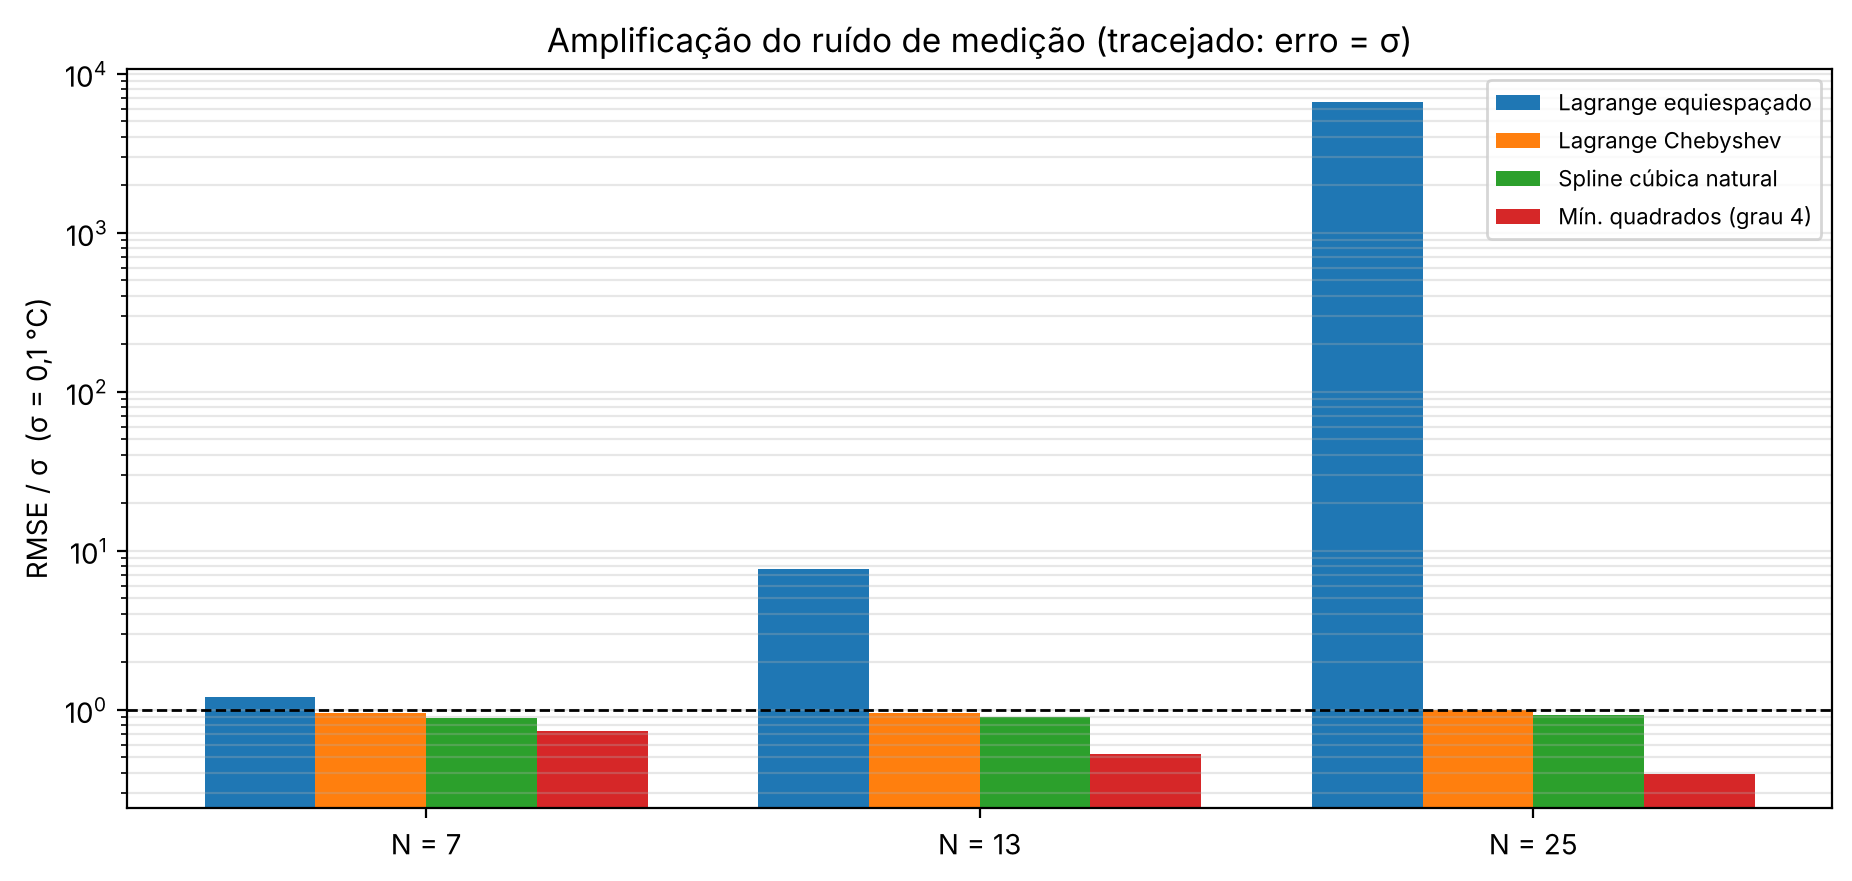

In [13]:
from numpy.polynomial import Chebyshev

rng = np.random.default_rng(2025)       # semente fixa => resultados reproduzíveis
rms = lambda v: float(np.sqrt(np.mean(np.square(v))))

def ajuste_mq(x, y, grau):
    """Regressão polinomial por mínimos quadrados (base de Chebyshev, bem condicionada). NÃO interpola os dados."""
    return Chebyshev.fit(x, y, grau, domain=[x_min, x_max])

def reconstruir(N, sigma, rng, grau_mq=4, impor_contorno=False):
    """Um experimento: N sensores com ruído gaussiano N(0, σ²) -> reconstruções avaliadas em x_fino.
    impor_contorno=True substitui as leituras das extremidades pelas temperaturas prescritas (Dirichlet, conhecidas)."""
    xe, xc = np.linspace(x_min, x_max, N), nos_chebyshev_lobatto(x_min, x_max, N)
    ye = temperatura_real(xe) + rng.normal(0, sigma, N)
    yc = temperatura_real(xc) + rng.normal(0, sigma, N)
    if impor_contorno:
        ye[[0, -1]] = temperatura_real([x_min, x_max]); yc[[0, -1]] = temperatura_real([x_min, x_max])
    return {"Lagrange equiespaçado": BarycentricInterpolator(xe, ye)(x_fino),
            "Lagrange Chebyshev":    BarycentricInterpolator(xc, yc)(x_fino),
            "Spline cúbica natural": CubicSpline(xe, ye, bc_type="natural")(x_fino),
            f"Mín. quadrados (grau {grau_mq})": ajuste_mq(xe, ye, grau_mq)(x_fino)}

n_mc = 300     # realizações de ruído por configuração (Monte Carlo)
linhas = []
for N in (7, 13, 25):
    for sigma in (0.0, 0.05, 0.1, 0.2):
        acum = {}
        for _ in range(1 if sigma == 0 else n_mc):
            for nome, Tr in reconstruir(N, sigma, rng).items():
                e = Tr - T_fino
                acum.setdefault(nome, []).append((np.sqrt(np.mean(e**2)), np.max(np.abs(e))))
        for nome, v in acum.items():
            v = np.array(v)
            linhas.append({"N": N, "σ (°C)": sigma, "Método": nome, "RMSE (°C)": v[:, 0].mean(), "Emax (°C)": v[:, 1].mean()})
df_ruido = pd.DataFrame(linhas)

for col in ("RMSE (°C)", "Emax (°C)"):
    print(f"\n{col} médio sobre {n_mc} realizações (σ = 0 é o caso sem ruído):")
    with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 220):
        display(df_ruido.pivot_table(index=["N", "σ (°C)"], columns="Método", values=col))

# Fator de amplificação do ruído = RMSE/σ (σ = 0,1 °C). RMSE/σ < 1 => o método REDUZ o ruído; > 1 => amplifica.
d = df_ruido[df_ruido["σ (°C)"] == 0.1].copy(); d["RMSE/σ"] = d["RMSE (°C)"]/0.1
fig, ax = plt.subplots(figsize=(11, 4.8))
metodos_nomes = list(d["Método"].unique()); larg = 0.2
for i, nome in enumerate(metodos_nomes):
    s = d[d["Método"] == nome]
    ax.bar(np.arange(3) + (i-1.5)*larg, s["RMSE/σ"].values, larg, label=nome)
ax.set_yscale("log"); ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xticks(range(3)); ax.set_xticklabels([f"N = {n}" for n in (7, 13, 25)])
ax.set_ylabel("RMSE / σ  (σ = 0,1 °C)"); ax.grid(alpha=0.3, axis="y", which="both"); ax.legend(fontsize=8)
ax.set_title("Amplificação do ruído de medição (tracejado: erro = σ)")
plt.show()

**Leitura dos resultados (σ = 0,1 °C):**

| N | Lagrange equi | Lagrange Cheb | Spline cúbica | Mín. quadrados (g. 4) |
|---|---|---|---|---|
| 7 | RMSE 0,12 | 0,096 | 0,089 | **0,073** |
| 13 | 0,77 | 0,096 | 0,090 | **0,053** |
| 25 | **≈ 660** | 0,100 | 0,093 | **0,039** |

1. **Interpoladores copiam o ruído:** como passam por todos os pontos, o erro fica da ordem de σ (RMSE/σ ≈ 0,9 a 1,0 para Chebyshev e spline, sem melhora ao aumentar N). Spline e Chebyshev ficam em torno de σ (a spline um pouco abaixo: entre os nós o erro de ruído pode ser menor que nos nós, onde é exatamente εᵢ).
2. **Lagrange equiespaçado amplifica o ruído** (Λ da Etapa 3): ×1,2 com 7 sensores, ×7,7 com 13 e ×6600 com 25; com N = 25 o erro médio é de centenas de °C, fisicamente absurdo. Mesmo o erro máximo para N = 13 (3,2 °C) já inviabiliza o método.
3. **A regressão de baixo grau reduz o ruído:** RMSE/σ ≈ 0,73, 0,53 e 0,39 para N = 7, 13, 25. *Mais sensores ajudam de fato*, porque a regressão promedia o ruído (a variância cai com a razão parâmetros/sensores). O custo é um **viés** pequeno: com σ = 0 o RMSE do grau 4 é ≈ 1·10⁻³ °C, desprezível frente ao ruído.
4. **Linearidade em σ.** Dobrar σ dobra o RMSE em cada linha da tabela: o erro devido ao ruído é ≈ σ·g(N, método), com g dependendo só do método e da geometria dos sensores. O erro máximo ≈ 2 a 2,5 × RMSE, de modo que as duas métricas contam a mesma história com escalas distintas.
5. **Implicação:** com ruído, o objetivo deixa de ser "passar pelos pontos"; é **suavizar**. Aumentar N só melhora a estimativa se o método fizer média.

### 4.2 Extremidades: onde o ruído é mais amplificado

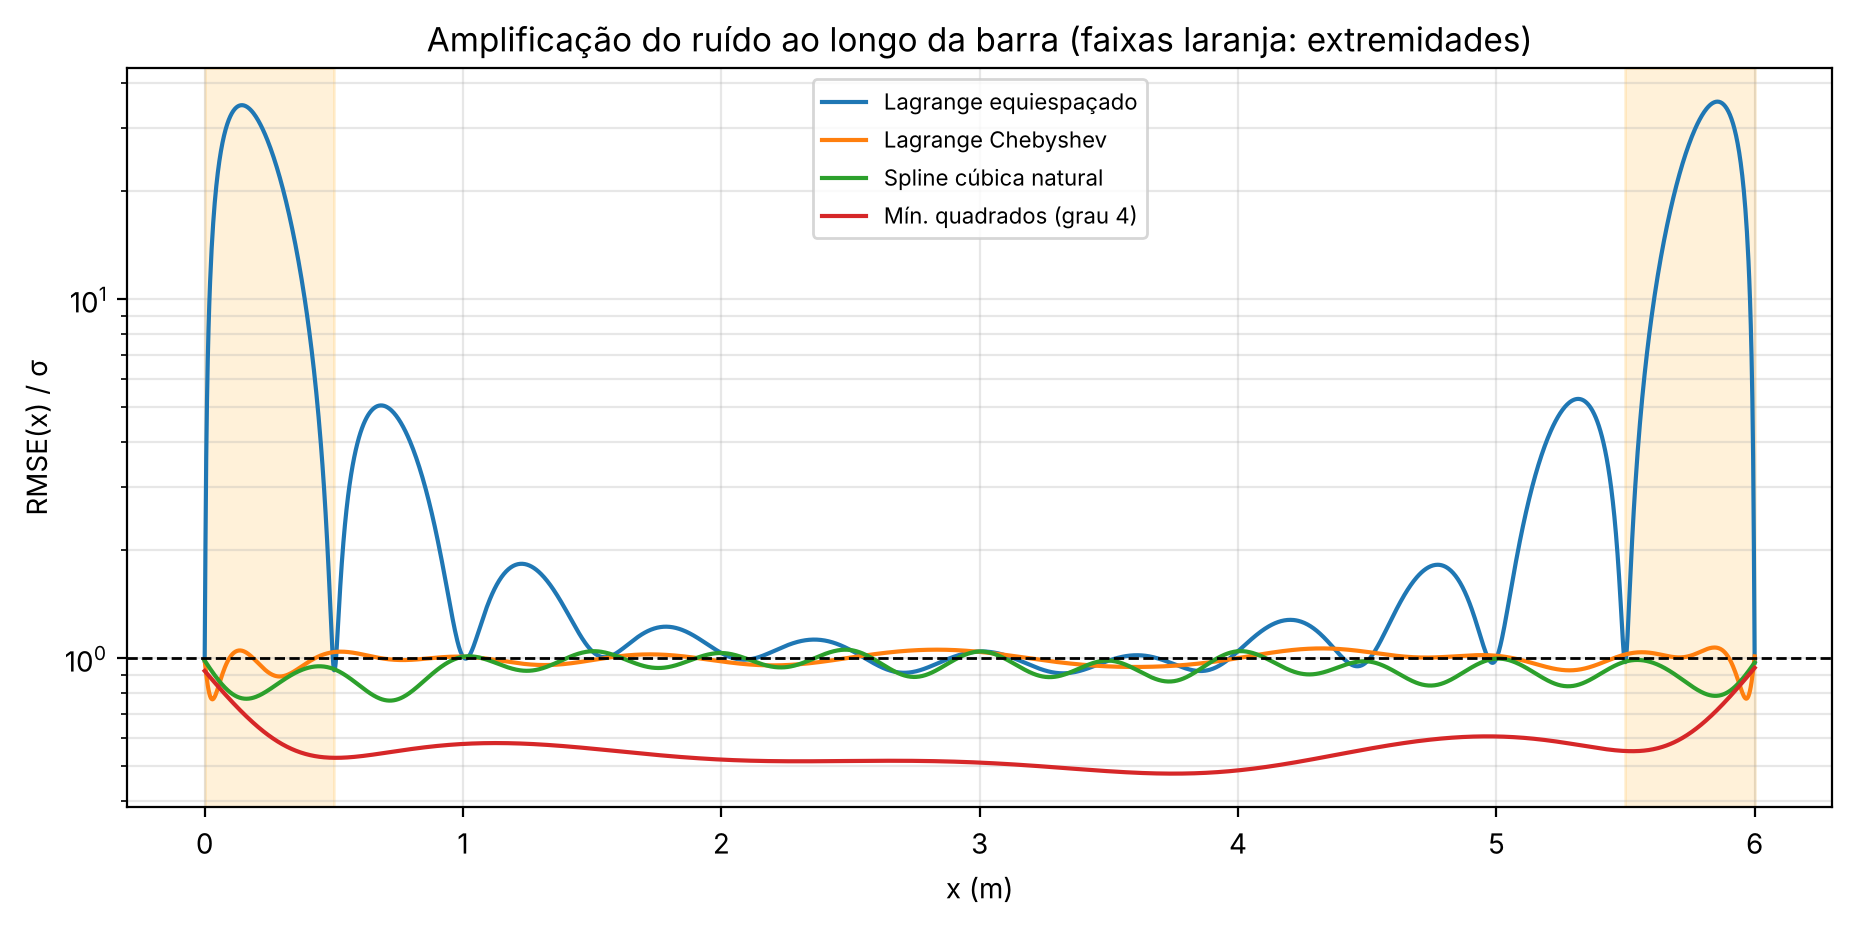

,"RMSE extremidades, sensor ruidoso","RMSE extremidades, contorno imposto","RMSE centro, sensor ruidoso","RMSE centro, contorno imposto"
Método,,,,
Lagrange equiespaçado,2.313,2.253,0.194,0.192
Lagrange Chebyshev,0.098,0.095,0.100,0.099
Spline cúbica natural,0.088,0.074,0.095,0.096
Mín. quadrados (grau 4),0.067,0.040,0.054,0.055


In [14]:
# Onde o ruído é mais amplificado? RMSE(x) por posição, N = 13, σ = 0,1 °C (Monte Carlo)
def mapa_posicao(N=13, sigma=0.1, n_mc=300, impor_contorno=False, rng=rng):
    soma = {}
    for _ in range(n_mc):
        for nome, Tr in reconstruir(N, sigma, rng, impor_contorno=impor_contorno).items():
            soma[nome] = soma.get(nome, 0) + (Tr - T_fino)**2
    return {nome: np.sqrt(s/n_mc) for nome, s in soma.items()}

mapa = mapa_posicao()
fig, ax = plt.subplots(figsize=(11, 4.8))
for nome, r in mapa.items():
    ax.semilogy(x_fino, r/0.1, label=nome)
ax.axhline(1, color="k", ls="--", lw=1)
ax.axvspan(0, 0.5, color="orange", alpha=0.15); ax.axvspan(5.5, 6, color="orange", alpha=0.15)
ax.set_xlabel("x (m)"); ax.set_ylabel("RMSE(x) / σ"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Amplificação do ruído ao longo da barra (faixas laranja: extremidades)")
plt.show()

# Extremidades x centro; leitura ruidosa x condição de contorno imposta (T(0), T(L) conhecidas)
zona_ext = (x_fino < 0.5) | (x_fino > 5.5)
mapa_bc = mapa_posicao(impor_contorno=True)
linhas = []
for nome in mapa:
    linhas.append({"Método": nome,
                   "RMSE extremidades, sensor ruidoso": np.sqrt(np.mean(mapa[nome][zona_ext]**2)),
                   "RMSE extremidades, contorno imposto": np.sqrt(np.mean(mapa_bc[nome][zona_ext]**2)),
                   "RMSE centro, sensor ruidoso": np.sqrt(np.mean(mapa[nome][~zona_ext]**2)),
                   "RMSE centro, contorno imposto": np.sqrt(np.mean(mapa_bc[nome][~zona_ext]**2))})
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 10):
    display(pd.DataFrame(linhas).set_index("Método"))

**Leitura dos resultados (N = 13, σ = 0,1 °C; extremidades = 0,5 m de cada ponta):**

- **Lagrange equiespaçado:** RMSE de **2,3 °C nas pontas contra 0,19 °C no centro**, uma amplificação ≈ 23σ nas bordas, exatamente onde o polinômio nodal é maior (ver Etapa 2).
- **Lagrange Chebyshev:** erro uniforme (≈ 0,10 em ambas as zonas), ≈ σ em todo lugar.
- **Spline cúbica:** 0,088 (pontas) vs 0,095 (centro), também uniforme.
- **Mínimos quadrados:** menor erro nas duas zonas (0,067 / 0,054); levemente maior nas pontas porque as extremidades têm mais *alavancagem* (leverage) na regressão.
- **Impor T(0) e T(L) conhecidos** (condição de contorno de Dirichlet, tratada como dado exato) reduz o erro nas pontas em ≈ 40 % para mínimos quadrados (0,067 → 0,040) e ≈ 16 % para a spline (0,088 → 0,074). Não ajuda o Lagrange equiespaçado (2,31 → 2,25): o erro ali vem do ruído dos sensores *interiores*, amplificado pelo polinômio global.
- **Sobre a spline "natural":** ela impõe T″ = 0 nas extremidades. Neste perfil isso é *exato* (T″(0) = T″(L) = 0, pois sen(0) = 0), o que explica por que a spline natural fica tão boa em [0, 6] m. É uma coincidência do perfil, não uma garantia; a seção 4.3 mostra o que acontece quando os sensores não estão onde T″ = 0.

### 4.3 Interpolação × extrapolação

Sem ruído (sensores em [0,6; 5,4] m):


,N,Método,Emax DENTRO (°C),Emax FORA (°C)
0,7,Lagrange equiespaçado,1.45e-05,5.21e-04
1,7,Lagrange Chebyshev,5.77e-06,3.39e-04
2,7,Spline cúbica natural,6.84e-03,7.90e-02
3,7,Spline cúbica not-a-knot,1.46e-03,2.04e-02
4,7,Mín. quadrados (grau 4),7.48e-04,1.23e-02
5,13,Lagrange equiespaçado,2.86e-12,1.82e-09
6,13,Lagrange Chebyshev,1.71e-13,6.39e-10
7,13,Spline cúbica natural,1.67e-03,7.64e-02
8,13,Spline cúbica not-a-knot,6.87e-05,4.24e-03
9,13,Mín. quadrados (grau 4),5.39e-04,1.22e-02


Com ruído σ = 0,1 °C, N = 13 (média de 300 realizações):


,Método,RMSE DENTRO (°C),RMSE FORA (°C)
0,Lagrange equiespaçado,0.734,341
1,Lagrange Chebyshev,0.0982,22.2
2,Spline cúbica natural,0.0913,0.181
3,Spline cúbica not-a-knot,0.0939,0.884
4,Mín. quadrados (grau 4),0.055,0.194


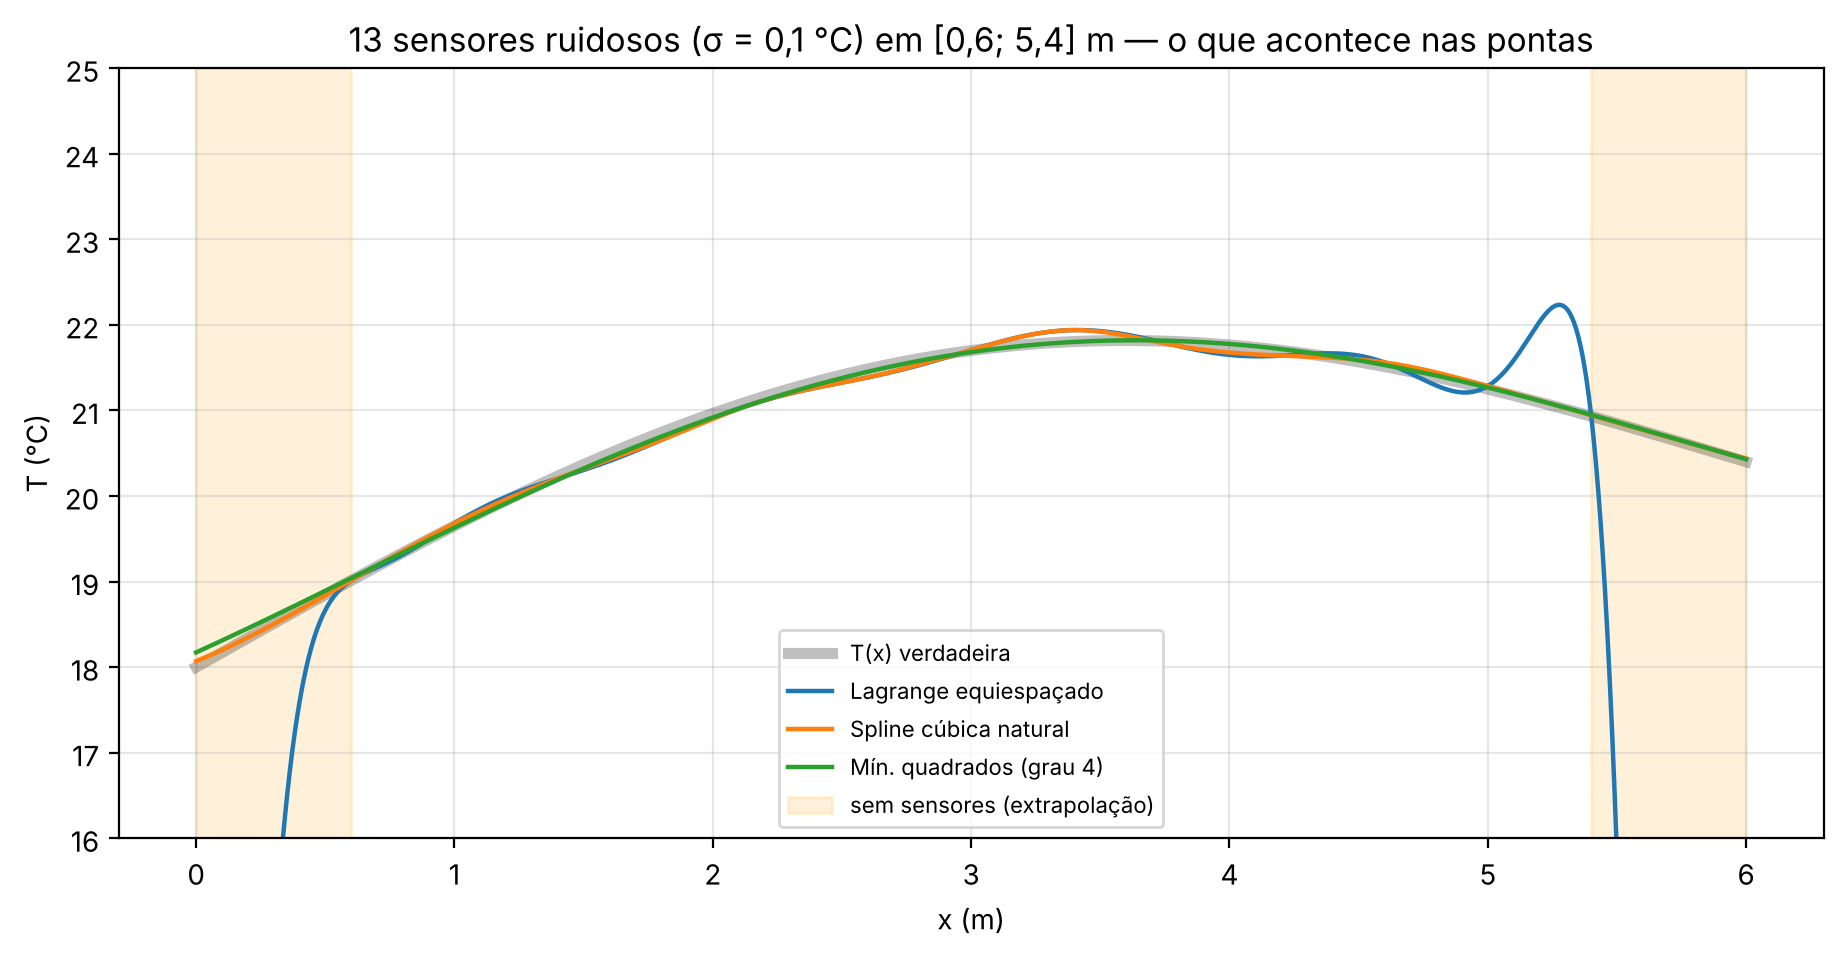

Efeito de usar T(0) e T(L) como dois nós extras (σ = 0,1 °C, N = 13, 300 realizações):


,RMSE pontas: só sensores,RMSE pontas: + contorno,redução nas pontas (×),RMSE centro: só sensores,RMSE centro: + contorno
Método,,,,,
Spline cúbica natural,0.177,0.075,2.362,0.091,0.091
Spline cúbica not-a-knot,0.901,0.117,7.681,0.093,0.091
Mín. quadrados (grau 4),0.190,0.036,5.322,0.055,0.046


In [15]:
# Interpolação (dentro do intervalo medido) x extrapolação (fora dele)
# Cenário: sensores só em [0,6; 5,4] m; as pontas da barra (0–0,6 m e 5,4–6 m) ficam SEM cobertura.
a, b = 0.6, 5.4
dentro = (x_fino >= a) & (x_fino <= b)

def metodos_cobertura(N, ruido=0.0, rng=rng, grau_mq=4):
    xe, xc = np.linspace(a, b, N), nos_chebyshev_lobatto(a, b, N)
    ye = temperatura_real(xe) + rng.normal(0, ruido, N) if ruido > 0 else temperatura_real(xe)
    yc = temperatura_real(xc) + rng.normal(0, ruido, N) if ruido > 0 else temperatura_real(xc)
    return {"Lagrange equiespaçado": BarycentricInterpolator(xe, ye)(x_fino),
            "Lagrange Chebyshev":    BarycentricInterpolator(xc, yc)(x_fino),
            "Spline cúbica natural": CubicSpline(xe, ye, bc_type="natural")(x_fino),
            "Spline cúbica not-a-knot": CubicSpline(xe, ye, bc_type="not-a-knot")(x_fino),
            f"Mín. quadrados (grau {grau_mq})": ajuste_mq(xe, ye, grau_mq)(x_fino)}

# (i) Sem ruído: Emax dentro x fora
linhas = []
for N in (7, 13):
    for nome, Tr in metodos_cobertura(N).items():
        e = np.abs(Tr - T_fino)
        linhas.append({"N": N, "Método": nome, "Emax DENTRO (°C)": e[dentro].max(), "Emax FORA (°C)": e[~dentro].max()})
print("Sem ruído (sensores em [0,6; 5,4] m):")
with pd.option_context("display.float_format", "{:.2e}".format):
    display(pd.DataFrame(linhas))

# (ii) Com ruído (σ = 0,1 °C): RMSE dentro x fora, média de 300 realizações (N = 13)
acum = {}
for _ in range(300):
    for nome, Tr in metodos_cobertura(13, ruido=0.1).items():
        e = Tr - T_fino
        acum.setdefault(nome, []).append((np.sqrt(np.mean(e[dentro]**2)), np.sqrt(np.mean(e[~dentro]**2))))
print("Com ruído σ = 0,1 °C, N = 13 (média de 300 realizações):")
linhas = [{"Método": n, "RMSE DENTRO (°C)": np.mean([t[0] for t in v]), "RMSE FORA (°C)": np.mean([t[1] for t in v])}
          for n, v in acum.items()]
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(linhas))

# Uma realização ruidosa para ver a extrapolação (eixo y limitado de propósito)
Tr = metodos_cobertura(13, ruido=0.1, rng=np.random.default_rng(7))
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x_fino, T_fino, "k", lw=4, alpha=0.25, label="T(x) verdadeira")
for nome in ("Lagrange equiespaçado", "Spline cúbica natural", "Mín. quadrados (grau 4)"):
    ax.plot(x_fino, Tr[nome], lw=1.6, label=nome)
ax.axvspan(0, a, color="orange", alpha=0.15); ax.axvspan(b, L, color="orange", alpha=0.15, label="sem sensores (extrapolação)")
ax.set_ylim(16, 25); ax.set_xlabel("x (m)"); ax.set_ylabel("T (°C)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("13 sensores ruidosos (σ = 0,1 °C) em [0,6; 5,4] m — o que acontece nas pontas")
plt.show()

# (iii) Aproveitar o que já se sabe: T(0) e T(L) são condições de contorno (exatas) => dois nós extras.
# A "extrapolação" nas pontas vira INTERPOLAÇÃO entre a borda e o primeiro sensor (mesmas realizações de ruído nas duas versões).
fora = ~dentro
rng_bc = np.random.default_rng(11)
construtores = {"Spline cúbica natural":    lambda x, y: CubicSpline(x, y, bc_type="natural"),
                "Spline cúbica not-a-knot": lambda x, y: CubicSpline(x, y, bc_type="not-a-knot"),
                "Mín. quadrados (grau 4)":  lambda x, y: ajuste_mq(x, y, 4)}
acum = {nome: [] for nome in construtores}
for _ in range(300):
    xe = np.linspace(a, b, 13); ye = temperatura_real(xe) + rng_bc.normal(0, 0.1, 13)
    xb = np.r_[x_min, xe, x_max]; yb = np.r_[temperatura_real(x_min), ye, temperatura_real(x_max)]
    for nome, constr in construtores.items():
        e0, e1 = constr(xe, ye)(x_fino) - T_fino, constr(xb, yb)(x_fino) - T_fino
        acum[nome].append((rms(e0[fora]), rms(e1[fora]), rms(e0[dentro]), rms(e1[dentro])))
linhas = []
for nome, v in acum.items():
    v = np.mean(v, axis=0)
    linhas.append({"Método": nome, "RMSE pontas: só sensores": v[0], "RMSE pontas: + contorno": v[1], "redução nas pontas (×)": v[0]/v[1],
                   "RMSE centro: só sensores": v[2], "RMSE centro: + contorno": v[3]})
print("Efeito de usar T(0) e T(L) como dois nós extras (σ = 0,1 °C, N = 13, 300 realizações):")
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 10):
    display(pd.DataFrame(linhas).set_index("Método"))

**Cenário:** sensores só entre 0,6 e 5,4 m; as pontas da barra (0–0,6 m e 5,4–6 m) ficam sem cobertura. *Interpolar* é estimar entre sensores; *extrapolar* é estimar fora do intervalo medido. (Como a barra só existe em [0, 6] m, "extrapolação" aqui significa região sem sensor, não além da barra.)

**Sem ruído:**

- Lagrange: o erro fora é **36×** (N = 7: 5,2·10⁻⁴ vs 1,4·10⁻⁵) e **≈ 600×** (N = 13: 1,7·10⁻⁹ vs 2,8·10⁻¹²) maior que dentro. Ainda é pequeno em valor absoluto porque o perfil é muito suave.
- **Spline natural:** erro fora ≈ 8·10⁻² °C que **não melhora com N** (7,9·10⁻² com N = 7, 7,6·10⁻² com N = 13). Motivo: nessas posições T″ ≠ 0 (T″(0,6) ≈ −0,21 °C/m²), mas a condição natural força S″ = 0, um **viés estrutural** que mais sensores não corrigem. Dentro do intervalo, a natural também é pior que a *not-a-knot* (N = 13: 1,7·10⁻³ vs 6,9·10⁻⁵).

**Com ruído (σ = 0,1 °C, N = 13):**

| Método | RMSE dentro | RMSE fora (pontas) |
|---|---|---|
| Lagrange equiespaçado | 0,73 | **≈ 340** |
| Lagrange Chebyshev | 0,098 | **≈ 22** |
| Spline natural | 0,091 | 0,18 |
| Spline not-a-knot | 0,094 | 0,88 |
| Mín. quadrados (grau 4) | **0,055** | 0,19 |

Polinômios de alto grau **explodem** fora do intervalo medido (de dezenas a centenas de °C). Modelos de baixa ordem degradam de forma limitada: ≈ 2× (spline natural) e ≈ 3,5× (mínimos quadrados); a *not-a-knot* já degrada ≈ 9×, porque extrapola com um cúbico ajustado às pontas, sem a curvatura forçada a zero.

**O que fazer na prática: usar o que já se sabe.** As temperaturas das extremidades são condições de contorno conhecidas. Incluí-las como dois nós extras transforma a extrapolação em interpolação e reduz o erro nas pontas em ≈ 2,4× (spline natural), ≈ 7,7× (not-a-knot) e ≈ 5,3× (mínimos quadrados), sem piorar o centro.

### 4.4 Sem a temperatura verdadeira: como estimar o erro em campo?

,LOO RMSE (campo),RMSE verdadeiro (só no experimento),√(LOO² − σ²)
Modelo,,,
Mín. quadrados grau 1,0.7692,0.7714,0.7627
Mín. quadrados grau 2,0.1182,0.07153,0.06308
Mín. quadrados grau 3,0.1225,0.07167,0.07073
Mín. quadrados grau 4,0.1127,0.04651,0.05195
Mín. quadrados grau 5,0.1162,0.04629,0.0592
Mín. quadrados grau 6,0.1214,0.04973,0.06886
Mín. quadrados grau 7,0.1214,0.05573,0.06884
Mín. quadrados grau 8,0.1289,0.05742,0.08138
Mín. quadrados grau 9,0.1399,0.05924,0.09787


Grau escolhido por LOO (frequência): {2: 45, 3: 5, 4: 84, 5: 19, 6: 11, 7: 8, 8: 9, 9: 11, 10: 8}
RMSE verdadeiro médio — grau escolhido por LOO: 0.0523 | grau fixo 4: 0.0409 | melhor grau (oráculo): 0.0404 | spline interpoladora: 0.0920  (°C)


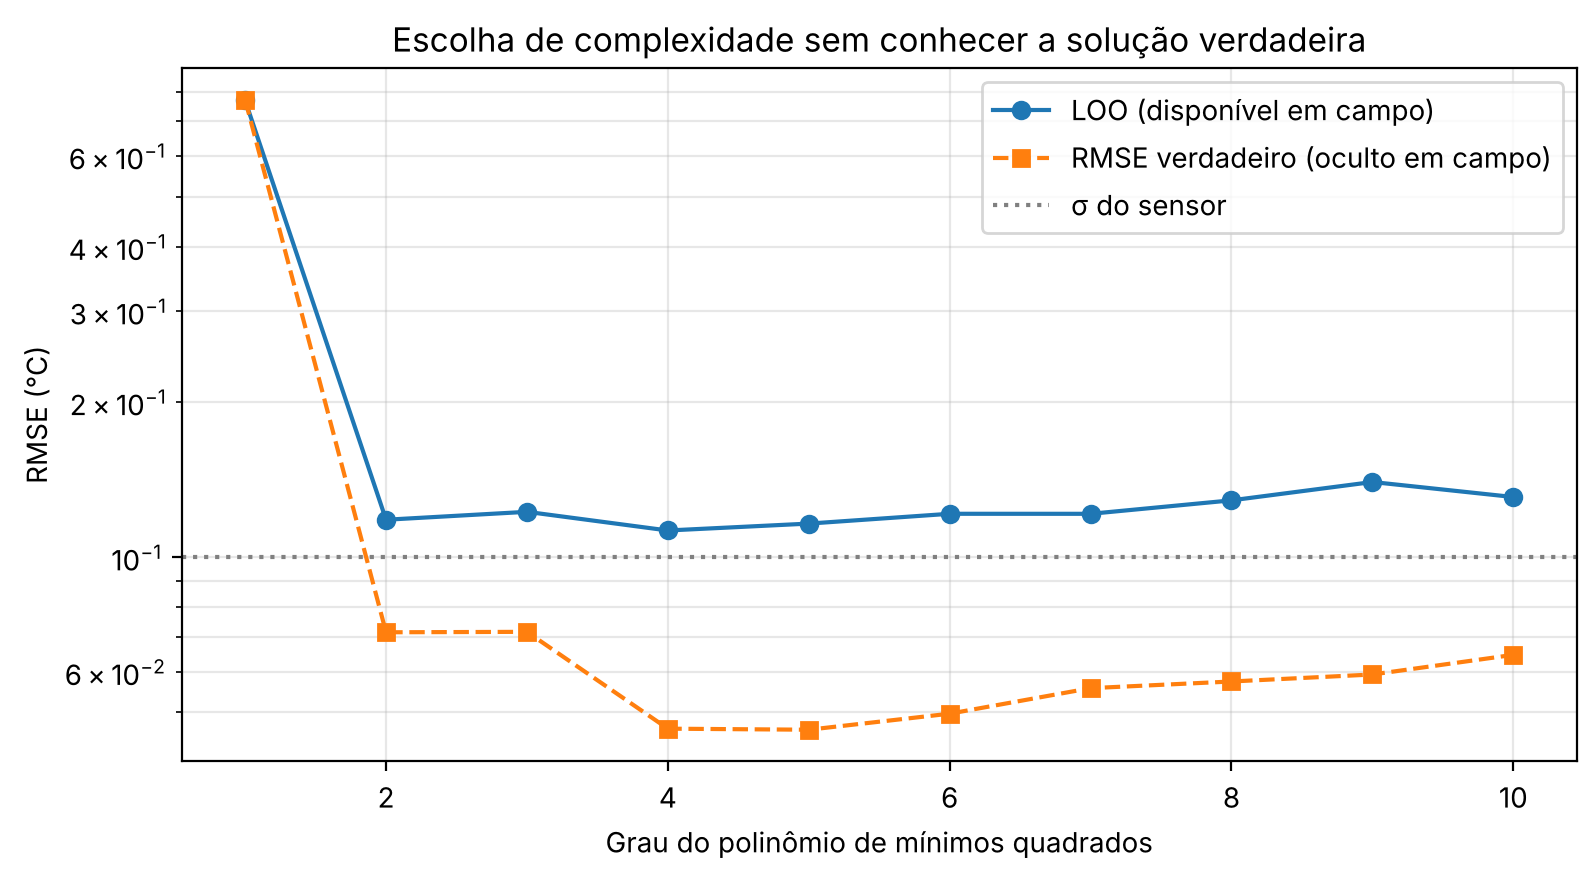

In [16]:
# Sem a temperatura verdadeira: como estimar o erro em campo? Validação cruzada leave-one-out (LOO).
# Ideia: retirar um sensor, reconstruir com os demais, prever o sensor retirado e medir o desvio.
N, sigma = 25, 0.1
xs = np.linspace(x_min, x_max, N)

def loo_mq(x, y, grau):
    """LOO exato para mínimos quadrados via matriz chapéu H: erro_i = r_i/(1 - H_ii). Retorna só os nós internos."""
    u = 2*(x - x_min)/(x_max - x_min) - 1
    V = np.polynomial.chebyshev.chebvander(u, grau)
    H = V @ np.linalg.pinv(V)
    r = (y - H @ y)/(1 - np.diag(H))
    return r[1:-1]

def loo_interp(x, y, construtor):
    """LOO por força bruta (refaz o interpolador sem o nó k); só nós internos (as pontas exigiriam extrapolar)."""
    erros = []
    for k in range(1, len(x)-1):
        m = np.ones(len(x), bool); m[k] = False
        erros.append(y[k] - construtor(x[m], y[m])(x[k]))      # observado − previsto (mesma convenção de loo_mq)
    return np.array(erros)

# Conferência: o atalho da matriz chapéu deve coincidir com a força bruta
y_teste = temperatura_real(xs) + rng.normal(0, sigma, N)
assert np.allclose(loo_mq(xs, y_teste, 4), loo_interp(xs, y_teste, lambda x, y: ajuste_mq(x, y, 4)))

y_obs = temperatura_real(xs) + rng.normal(0, sigma, N)          # UMA realização de sensores ruidosos
linhas = []
for grau in range(1, 11):
    f = ajuste_mq(xs, y_obs, grau)
    linhas.append({"Modelo": f"Mín. quadrados grau {grau}", "LOO RMSE (campo)": rms(loo_mq(xs, y_obs, grau)),
                   "RMSE verdadeiro (só no experimento)": rms(f(x_fino) - T_fino)})
for nome, constr in (("Spline cúbica natural (interpola)", lambda x, y: CubicSpline(x, y, bc_type="natural")),
                     ("Lagrange equiespaçado (interpola)", lambda x, y: BarycentricInterpolator(x, y))):
    linhas.append({"Modelo": nome, "LOO RMSE (campo)": rms(loo_interp(xs, y_obs, constr)),
                   "RMSE verdadeiro (só no experimento)": rms(constr(xs, y_obs)(x_fino) - T_fino)})
tab_loo = pd.DataFrame(linhas).set_index("Modelo")
tab_loo["√(LOO² − σ²)"] = np.sqrt(np.maximum(tab_loo["LOO RMSE (campo)"]**2 - sigma**2, 0))
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 220):
    display(tab_loo)

# Robustez: escolher o grau pelo LOO funciona na média? (200 realizações)
escolhidos, rmse_esc, rmse_g4, rmse_orac, rmse_spl = [], [], [], [], []
for _ in range(200):
    y = temperatura_real(xs) + rng.normal(0, sigma, N)
    loo = [rms(loo_mq(xs, y, g)) for g in range(1, 11)]
    verd = [rms(ajuste_mq(xs, y, g)(x_fino) - T_fino) for g in range(1, 11)]
    g_esc = int(np.argmin(loo)) + 1
    escolhidos.append(g_esc); rmse_esc.append(verd[g_esc-1]); rmse_g4.append(verd[3]); rmse_orac.append(min(verd))
    rmse_spl.append(rms(CubicSpline(xs, y, bc_type="natural")(x_fino) - T_fino))
print("Grau escolhido por LOO (frequência):", dict(sorted(pd.Series(escolhidos).value_counts().items())))
print(f"RMSE verdadeiro médio — grau escolhido por LOO: {np.mean(rmse_esc):.4f} | grau fixo 4: {np.mean(rmse_g4):.4f} | "
      f"melhor grau (oráculo): {np.mean(rmse_orac):.4f} | spline interpoladora: {np.mean(rmse_spl):.4f}  (°C)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogy(range(1, 11), tab_loo["LOO RMSE (campo)"].iloc[:10], "o-", label="LOO (disponível em campo)")
ax.semilogy(range(1, 11), tab_loo["RMSE verdadeiro (só no experimento)"].iloc[:10], "s--", label="RMSE verdadeiro (oculto em campo)")
ax.axhline(sigma, color="gray", ls=":", label="σ do sensor")
ax.set_xlabel("Grau do polinômio de mínimos quadrados"); ax.set_ylabel("RMSE (°C)"); ax.grid(alpha=0.3, which="both"); ax.legend()
ax.set_title("Escolha de complexidade sem conhecer a solução verdadeira")
plt.show()

**Leitura dos resultados (N = 25, σ = 0,1 °C):**

1. **O LOO é computável em campo e orienta a escolha.** Para o grau 4, o LOO foi 0,113 °C e o RMSE verdadeiro (oculto) foi 0,047 °C. O LOO é maior porque o erro de validação contém o **ruído da medição retirada**: LOO² ≈ RMSE_verdadeiro² + σ². Se σ é conhecido (folha de dados/calibração), √(LOO² − σ²) é uma estimativa do erro verdadeiro: para a spline deu 0,099 contra 0,0998 verdadeiro; para o grau 4, 0,052 contra 0,047. Em graus altos tende a superestimar.
2. **O LOO denuncia instabilidade.** Para Lagrange equiespaçado o LOO foi ≈ 2400 °C: um sinal inequívoco de que o método é inutilizável com esses dados, mesmo sem conhecer a verdade.
3. **Escolher o grau pelo LOO funciona na média, mas é ruidoso.** Em 200 realizações o grau 4 foi escolhido 84 vezes, o grau 2 em 45; o RMSE verdadeiro médio foi 0,052 °C com grau escolhido por LOO, contra 0,092 °C da spline interpoladora (≈ 43 % menor). O grau 4 fixo (0,041 °C) e o melhor grau do "oráculo" (0,040 °C) *não são opções honestas em campo*: usam conhecimento da solução verdadeira. A curva de LOO é quase plana entre os graus 2 e 7; vale preferir o modelo mais simples dentro da margem de ruído do LOO.

**Limites desta validação:** ela só mede o erro **nas posições dos sensores** (e só nos interiores); não diz nada sobre regiões sem sensor nem sobre extrapolação; supõe ruído independente e σ conhecido; e **não detecta erro de modelo** (calibração enviesada de sensores, propriedades térmicas reais variando, perdas laterais, contorno incerto).

### 4.5 Recomendação técnica

**Parte da recomendação baseada nas métricas RMSE e erro máximo (Emax) obtidas acima.** A solução analítica foi usada só como régua de laboratório.

#### Resumo da decisão

| Situação | Recomendação | Evidência |
|---|---|---|
| Poucos sensores (N ≤ 6), exatos, perfil de suavidade incerta | **Spline cúbica** | N = 4: RMSE 4,8·10⁻³ vs 6,8·10⁻² (Lagrange equi); N = 6: RMSE 5,1·10⁻⁴ e Emax 1,1·10⁻³ (Lagrange equi: RMSE 1,5·10⁻³, Emax 3,3·10⁻³) |
| N ≥ 7, exatos, posições livres, perfil suave | **Lagrange com nós de Chebyshev** | N = 9: Emax 2·10⁻⁷ °C; piso ~10⁻¹⁴ °C a partir de N ≈ 15 |
| Posições fixas equiespaçadas, N grande ou suavidade duvidosa | **Spline cúbica** (evitar Lagrange equi para N ≳ 15) | N = 40: Emax 2,8·10⁻⁷ vs ~10⁻⁵ do Lagrange equi |
| **Sensores com ruído** | **Regressão de baixo grau / spline de suavização**, grau escolhido por validação cruzada | N = 13, σ = 0,1: RMSE 0,053 vs 0,090 (spline interpoladora); N = 25: 0,039 vs 0,093; Emax 0,10 vs 0,23 |

#### Respostas às cinco perguntas

**1. Poucos sensores exatos.** Com N ≤ 6, a **spline cúbica** (4 sensores: RMSE 4,8·10⁻³ °C; Lagrange equi 6,8·10⁻²). Com os 7 sensores da Etapa 1, o Lagrange global é mais preciso (RMSE 3,3·10⁻⁵ vs 2,4·10⁻⁴ °C), **mas só porque o perfil é suave**; sem garantia disso, a spline é a escolha segura, pois é local, não oscila e seu erro é controlado (∝ h⁴).

**2. Aumentando o número de sensores.** A spline melhora de forma previsível (≈ 16× por duplicação de N). O Lagrange com Chebyshev converge geometricamente (≈ 12× por sensor) até ~10⁻¹⁴ °C em N ≈ 15; o equiespaçado atinge o melhor erro em N ≈ 15 e **piora** depois (≈ 10⁻⁵ °C em N = 40, por amplificação de arredondamento, Λ ≈ 2·10⁹). Passar de ~15 sensores não traz ganho de interpolação: o limite passa a ser o ruído dos sensores (σ ≥ 0,05 °C ≫ 10⁻⁶ °C).

**3. Sensores ruidosos.** **Não interpolar.** Interpoladores copiam o ruído (RMSE ≈ σ) e o Lagrange equiespaçado o amplifica (×7,7 com N = 13; ×6600 com N = 25). Usar **mínimos quadrados de baixo grau** (ou spline de suavização), que reduz o erro abaixo de σ e melhora com N (RMSE/σ ≈ 0,73 → 0,53 → 0,39 para N = 7, 13, 25). Escolher o grau por **validação cruzada leave-one-out**, não por palpite. Se for imprescindível interpolar, usar spline ou nós de Chebyshev (erro ≈ σ).

**4. Cuidados nas extremidades.** (i) **Impor as condições de contorno conhecidas T(0) e T(L)** como dados exatos: reduz o erro nas pontas em 40 % (mín. quadrados) e transforma extrapolação em interpolação quando não há sensor na borda (erro nas pontas cai 2,4× a 7,7×). (ii) Evitar polinômios globais de alto grau em nós equiespaçados: o erro nas pontas chega a 23σ. (iii) A condição natural (S″ = 0) só é correta se T″ = 0 na borda, como neste perfil; caso contrário use *not-a-knot* ou imponha a derivada/curvatura que a física indicar. (iv) Se puder escolher posições, concentrar sensores nas pontas (Chebyshev).

**5. Limitações quando a verdade é desconhecida.**

- O erro só pode ser **estimado**, por validação cruzada nos sensores, e √(LOO² − σ²) exige σ conhecido; a estimativa é ruidosa e vale só *onde há sensores*.
- **Erro de modelo** é invisível aos experimentos: o perfil analítico é uma idealização (propriedades k(x), perdas laterais, regime transiente, contorno incerto, geração de calor localizada). Fontes concentradas criam estruturas não suaves em que o ótimo deste notebook (Lagrange/Chebyshev) pode falhar, como mostra o contraponto de Runge.
- **Viés sistemático** (calibração) não se reduz por promediação.
- **Interpolação ≠ extrapolação.** Dentro do intervalo medido o erro é ≈ σ ou menor; fora dele é 12× a 600× maior (sem ruído) e chega a centenas de °C com polinômios de alto grau e ruído. Reportar as estimativas **com incerteza** (por exemplo ±2·RMSE estimado) e **marcar as regiões extrapoladas** como de baixa confiança.
- Os resultados foram obtidos para um perfil suave, ruído gaussiano independente e uma única geometria de sensores; devem ser refeitos antes de generalizar.

---
### Observações finais

- **Reprodutibilidade:** os experimentos com ruído usam semente fixa; a execução completa leva de alguns segundos a cerca de um minuto, conforme a máquina. Valores perto do piso de arredondamento (Etapa 3) podem variar levemente entre execuções.
- **Ideia central do trabalho:** o erro total de um interpolador tem três fontes que se somam: *truncamento* (a função não é um polinômio/spline), *arredondamento amplificado* pela constante de Lebesgue e *ruído amplificado* pelo mesmo fator. Cada método e cada distribuição de nós distribui essas três fontes de modo diferente, e é isso que torna a escolha dependente de N, da posição dos sensores e do ruído.